# Task 3 – CIGRE-Mittelspannungsnetz

**Ziel:** Das Mittelspannungs-Testnetz CIGRE-MV wird in pandapower aufgebaut, mit einem Lastfluss berechnet und ausgewertet (Busspannungen, Leitungsauslastungen). Anschließend wird es um das Ortsnetz aus Task 2 mit saisonaler Einspeisung erweitert.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofil der Haushalte, Windenergieanlage, PV-Anlage, Wetterdaten
2. Netzaufbau CIGRE-MV: Netzplan und Komponenten
3. Lastfluss, Ergebnisse und Auswertung (statisch und saisonal über 12 typische Wochen)
4. Erweiterung um das Ortsnetz aus Task 2 *(folgt)*

## Importe

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

# Alle Module liegen im Ordner dieses Notebooks (task3)
TASK3 = Path(".")
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task3` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) und Komponentenübersicht des Netzes
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv` | BDEW-Standardlastprofile H25 (Haushalt) und G25 (Gewerbe), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [3]:
DATA = TASK3 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche

ANNUAL_KWH = 3500                                               # Jahresverbrauch eines Haushalts [kWh/a]

for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
P25 – Haushalt mit PV (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
S25 – Haushalt mit PV und Speicher (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


### 1.1 Lastprofile (BDEW H25 und G25)

#### Haushalte (H25)

**Herkunft:** Das Standardlastprofil H25 ist der Nachfolger des Haushaltsprofils H0 aus dem Jahr 1999. Es wurde im Auftrag des BDEW von der BTU EVU Beratung GmbH aus Abrechnungsdaten von 62 Verteilnetzbetreibern der Jahre 2018 und 2019 erstellt [1, S. 3]. Weil zu dieser Zeit bereits PV-Anlagen in Betrieb waren, enthält das Profil einen moderaten PV-Eigenverbrauch [1, S. 3]. Die Daten stammen aus der BDEW-Veröffentlichung der repräsentativen Profile 2025 [2].

**Aufbau der Datei:** 12 Monate × 3 Tagtypen (WT = Werktag, SA = Samstag, FT = Sonn- und Feiertag) mit je 96 Viertelstundenwerten. Die Werte sind Energiemengen in kWh je Viertelstunde, normiert auf einen Jahresverbrauch von 1 Mio. kWh [1, S. 3].

**Aufbereitung:**

1. *Woche bilden:* Montag bis Freitag erhalten den Tagtyp WT, Samstag SA, Sonntag FT. Wochen mit gesetzlichem Feiertag (NRW) werden bei der Auswahl der Wochen ausgeschlossen, damit die Annahme „fünf Werktage“ gilt.
2. *Leistung:* Die Energie einer Viertelstunde wird in die mittlere Leistung umgerechnet: P = E / 0,25 h = 4 · E.
3. *Dynamisierung:* H25 ist „entdynamisiert“; beim Ausrollen ist die Dynamisierungsfunktion anzuwenden [1, S. 3–4]. Sie bildet den Jahresgang des Verbrauchs ab (im Winter höher, im Sommer niedriger):

   F(t) = −3,92·10⁻¹⁰·t⁴ + 3,2·10⁻⁷·t³ − 7,02·10⁻⁵·t² + 2,1·10⁻³·t + 1,24 &nbsp;&nbsp; (t = Tag des Jahres) [3]

   Der Faktor wird auf vier Nachkommastellen gerundet [1, S. 4] und liegt zwischen etwa 0,79 (Juli/August) und 1,26 (Ende Dezember).
4. *Skalierung:* P_Haushalt = P_norm · F(t) · W_a / 1 000 000 kWh mit dem Jahresverbrauch W_a des Haushalts.
5. *Stundenwerte:* Mittelwert der vier Viertelstundenleistungen einer Stunde.

**Vorzeichen und Einheiten:** Die Last wird im Verbraucherzählpfeilsystem angegeben (Bezug positiv), in pandapower in MW (`unit="MW"`). Die Blindleistung ist im Profil nicht enthalten und wird bei der Einbindung ins Netz über einen Leistungsfaktor festgelegt.

#### Gewerbe (G25)

**Herkunft:** G25 („Gewerbe allgemein“) ist das Standardlastprofil für Gewerbekunden aus derselben BDEW-Veröffentlichung 2025 wie H25 [2]. Es ersetzt das frühere Profil G0 und beschreibt einen durchschnittlichen Gewerbebetrieb ohne ausgeprägte Branchencharakteristik.

**Aufbau:** wie H25 – 12 Monate × 3 Tagtypen (WT, SA, FT) mit je 96 Viertelstundenwerten in kWh, normiert auf 1 Mio. kWh Jahresverbrauch.

**Unterschied zu H25:** Für G25 ist die Dynamisierungsfunktion **nicht** anzuwenden (Hinweis im Dateikopf und [1]). Die Aufbereitung beschränkt sich daher auf Wochenbildung, Umrechnung in Leistung (P = 4 · E), Skalierung auf den Jahresverbrauch und Mittelung auf Stundenwerte.

**Verwendung:** Im CIGRE-Netz gibt es Wohngebietslasten (R, *residential*) und Gewerbe-/Industrielasten (CI, *commercial/industrial*). Für die zeitliche Variation der R-Lasten wird H25, für die CI-Lasten G25 verwendet.

**Darstellung:** Für jeden Monat werden beide Profile für eine Woche in Stundenwerten gezeigt. Damit die Verläufe direkt vergleichbar sind, sind beide auf denselben Jahresverbrauch von 1 Mio. kWh bezogen (H25 dynamisiert, G25 ohne Dynamisierung). Die Woche liegt auf denselben Kalendertagen wie die typische Wetterwoche des Monats (Abschnitt 1.4), sodass Last und Erzeugung später direkt kombiniert werden können.

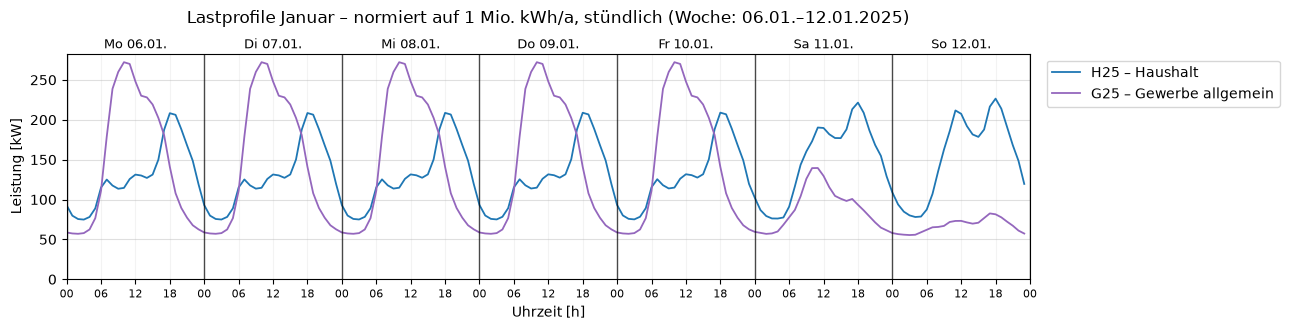

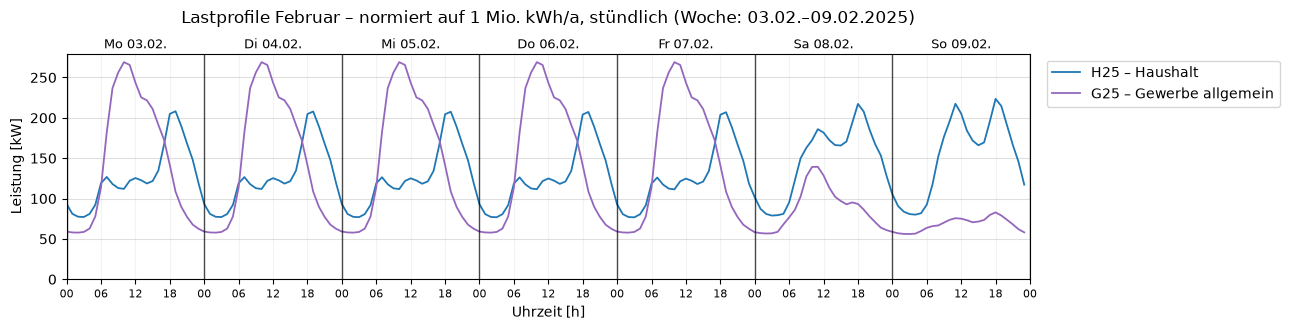

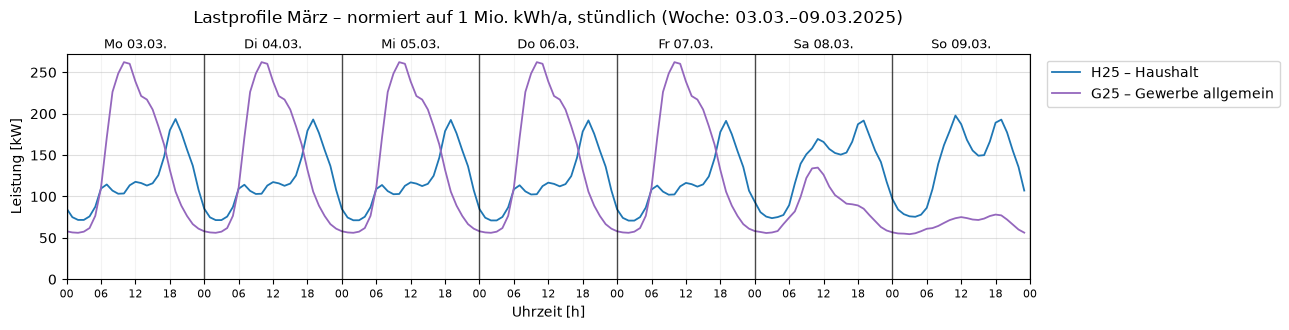

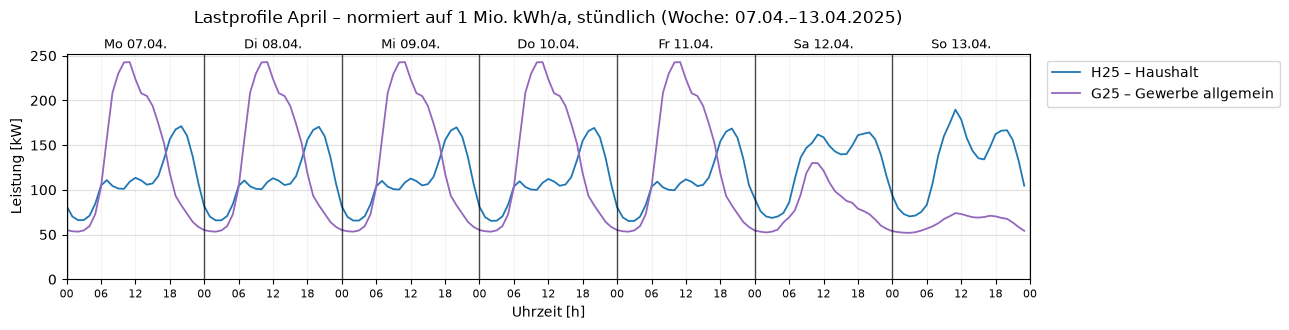

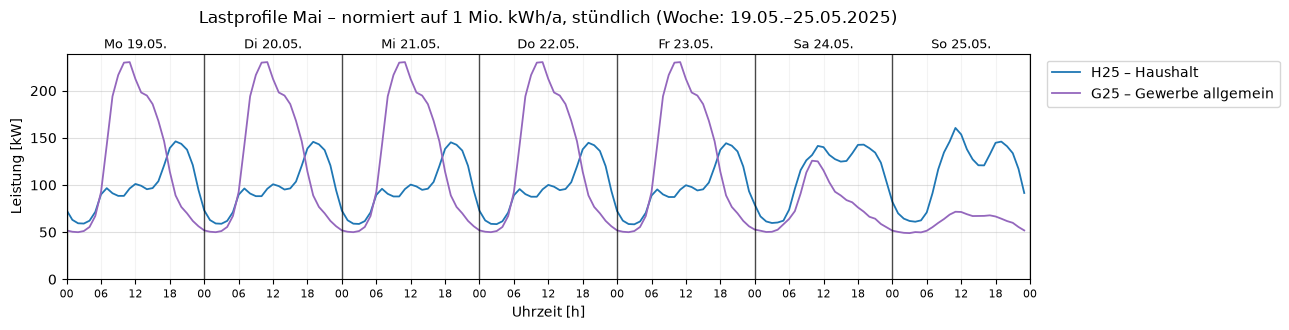

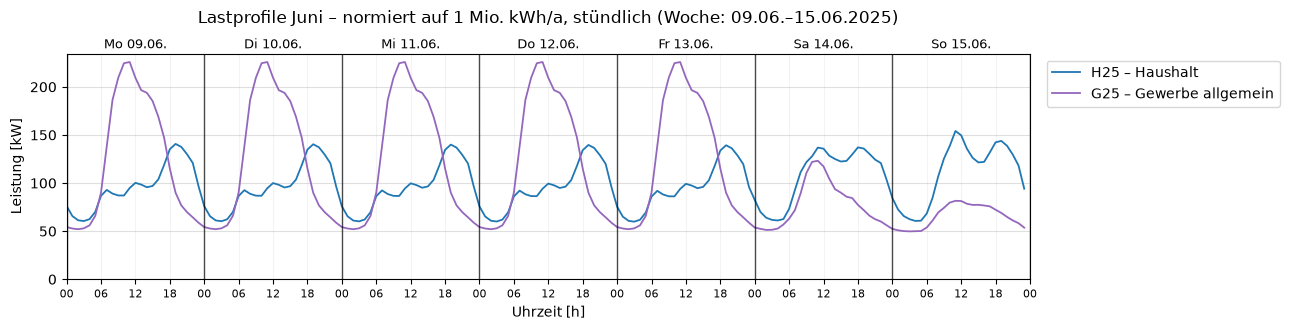

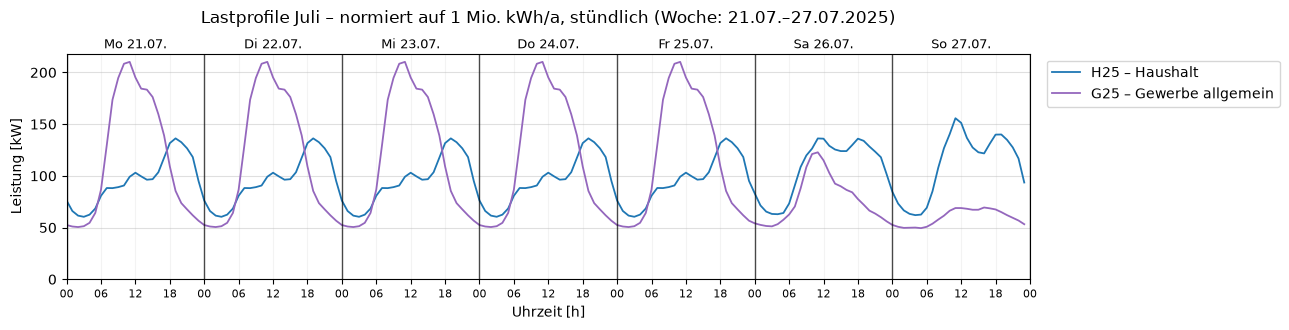

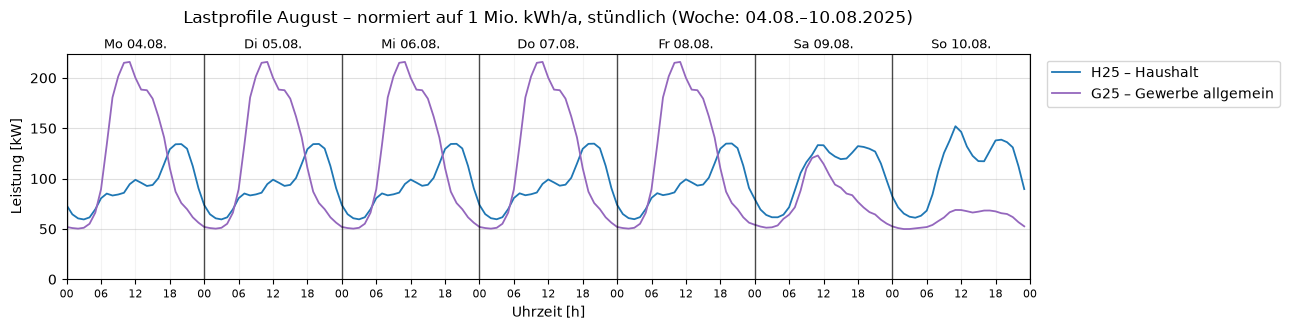

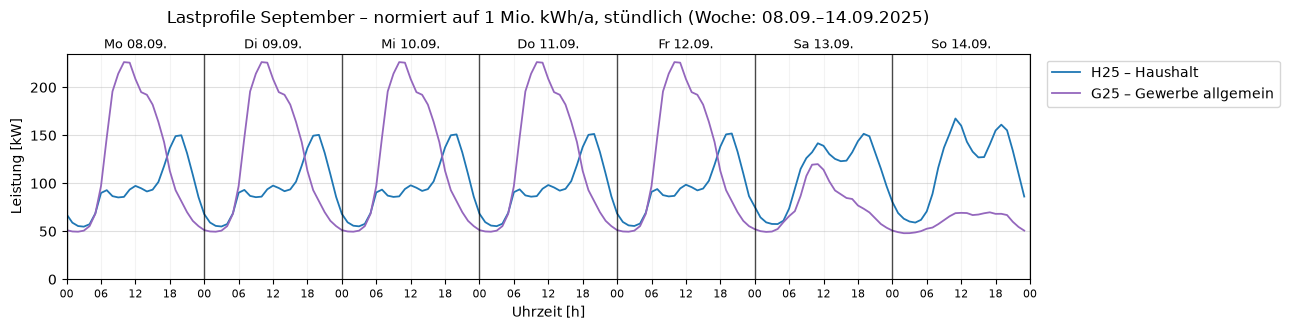

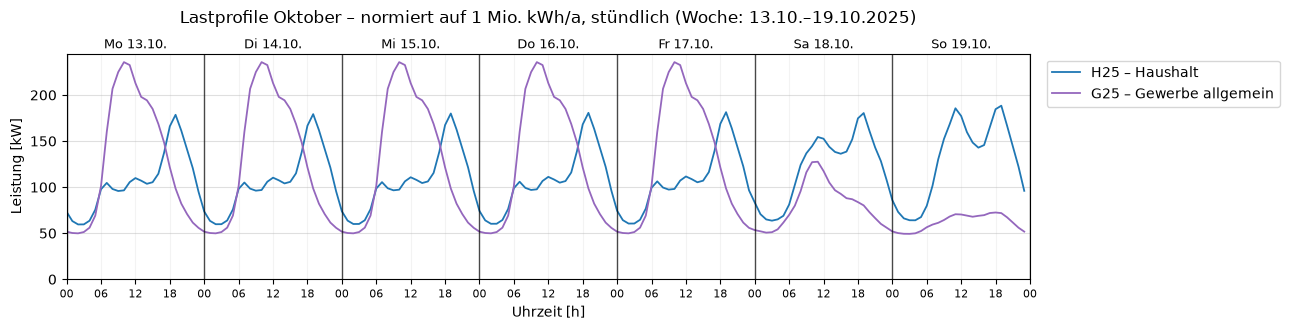

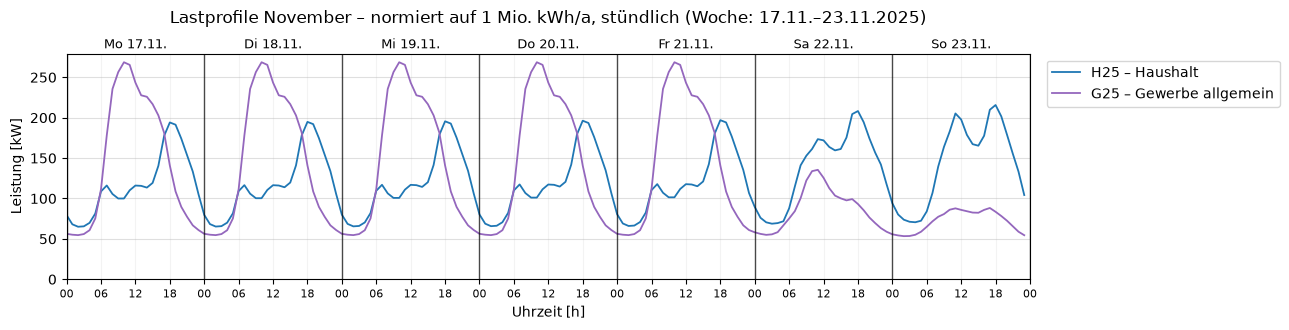

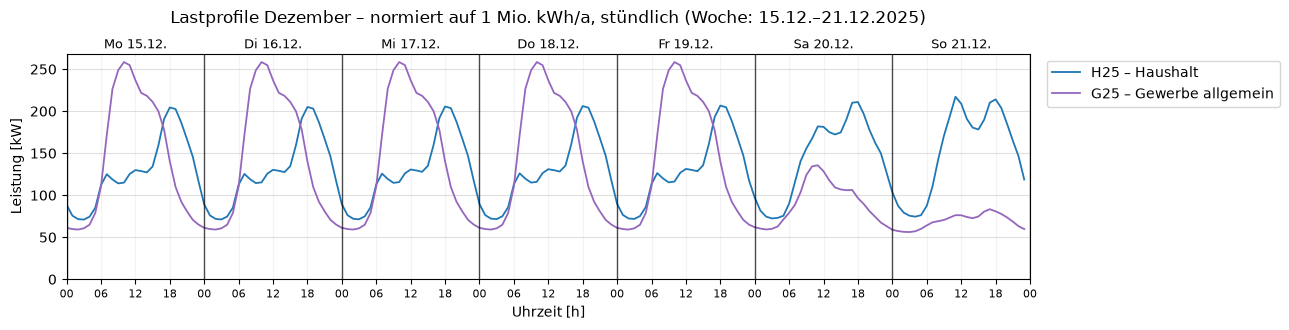

In [4]:
LOAD_PROFILES = [Lastprofil.HAUSHALT, Lastprofil.GEWERBE]

for month in Month:
    weeks = {p.label: pr.build_week(PROFILES, p, month, annual_kwh=pr.NORM_KWH, unit="kW",
                                    start=WEEK_STARTS[month], resolution="1h")
             for p in LOAD_PROFILES}
    first = next(iter(weeks.values()))
    plots.plot_load_week(weeks, f"Lastprofile {month.label} – normiert auf 1 Mio. kWh/a, stündlich "
                                f"(Woche: {first.index[0]:%d.%m.}–{first.index[-1]:%d.%m.%Y})")
    plt.show()

**Wochenenergie je Monat** (normiert auf 1 Mio. kWh/a; ein Jahr hat 52,1 Wochen, im Mittel also etwa 19 200 kWh je Woche):

In [5]:
energy = pd.DataFrame({
    p.label: [pr.build_week(PROFILES, p, m, start=WEEK_STARTS[m], resolution="1h").sum() for m in Month]
    for p in LOAD_PROFILES
}, index=[m.label for m in Month])
energy["Verhältnis G25/H25"] = energy.iloc[:, 1] / energy.iloc[:, 0]
energy.round(2)

,H25 – Haushalt,G25 – Gewerbe allgemein,Verhältnis G25/H25
Januar,22719.75,21518.05,0.95
Februar,22299.51,21289.32,0.95
März,20474.20,20684.52,1.01
April,19315.88,19364.30,1.00
Mai,16945.86,18328.34,1.08
Juni,16707.49,18356.55,1.10
Juli,16655.36,17388.90,1.04
August,16270.44,17708.41,1.09
September,16721.62,18225.32,1.09
Oktober,18761.87,18857.81,1.01


**Vergleich der Profile:**

- **H25 (Haushalt):** Morgen- und ausgeprägte Abendspitze (ca. 18–20 Uhr), am Wochenende höherer Verbrauch über den Tag. Durch die Dynamisierung ist der Verbrauch im Winter deutlich höher als im Sommer.
- **G25 (Gewerbe):** hohe Leistung an Werktagen während der Betriebszeiten (etwa 7–17 Uhr, Maximum vormittags), deutlich niedrigere Leistung nachts, samstags und vor allem sonntags. Der Jahresgang ist schwächer, weil keine Dynamisierung angewendet wird.
- Die Lastspitzen fallen zeitlich auseinander: Gewerbe tagsüber, Haushalte abends. Gewerbelasten fallen damit zeitlich besser mit der PV-Erzeugung zusammen als Haushaltslasten.

### 1.2 Windenergieanlage (Vestas V90-2.0 MW)

**Anlagendaten** [7]: Nennleistung 2,0 MW, Rotordurchmesser 90 m (überstrichene Fläche A ≈ 6 362 m²), Nabenhöhen 80 / 95 / 105 m, Einschaltgeschwindigkeit 4 m/s, Nenngeschwindigkeit 13 m/s, Abschaltgeschwindigkeit 25 m/s. Verwendet wird eine Nabenhöhe von 105 m.

**Physikalischer Hintergrund:** Die im Wind enthaltene Leistung, die durch die Rotorfläche strömt, ist

P_Wind = ½ · ρ · A · v³

mit der Luftdichte ρ ≈ 1,225 kg/m³. Eine Windenergieanlage kann davon nur den Anteil c_p (Leistungsbeiwert) entnehmen; theoretisch höchstens c_p,Betz = 16/27 ≈ 0,59 [9]. Real erreichte Werte und die Regelung der Anlage sind in der **Leistungskennlinie** P(v) zusammengefasst, die der Hersteller für eine Standard-Luftdichte angibt. Sie hat vier Bereiche [9]:

| Bereich | Windgeschwindigkeit | Leistung |
|---|---|---|
| Stillstand | v < v_ein | 0 |
| Teillast | v_ein ≤ v < v_Nenn | steigt etwa mit v³ |
| Volllast | v_Nenn ≤ v < v_ab | Nennleistung (Pitch-Regelung begrenzt die Leistung) |
| Sturmabschaltung | v ≥ v_ab = 25 m/s | 0 |

**Kennlinie:** Die Stützstellen (Schrittweite 0,5 m/s) stammen aus der Turbinendatenbank der Open Energy Database (OEDB), die mit der Python-Bibliothek *windpowerlib* ausgeliefert wird; als Quelle ist dort die oben genannte Herstellerangabe auf wind-turbine-models.com eingetragen [8]. Zwischen den Stützstellen wird linear interpoliert. Die Tabelle beginnt bereits bei 3,5 m/s mit 42 kW, während [7] eine Einschaltgeschwindigkeit von 4 m/s nennt. Oberhalb von 12,5 m/s wird die Nennleistung von 2 000 kW angesetzt.

**Höhenumrechnung:** Die Windgeschwindigkeit nimmt mit der Höhe zu. Die API liefert sie in 100 m Höhe; auf die Nabenhöhe h wird mit dem Potenzgesetz umgerechnet [9]:

v_Nabe = v_100 · (h / 100 m)^α, &nbsp; α = 1/7

Bei h = 105 m ergibt sich ein Faktor von 1,007. Der Einfluss ist also gering.

**Vereinfachungen:** keine Korrektur der Luftdichte (Temperatur, Höhe), keine Verfügbarkeitsverluste, keine Abschattung durch andere Anlagen, Stundenwerte statt Böen.

**Normierung:** Neben der Leistung in kW wird die Leistung bezogen auf die Nennleistung gespeichert (`wind_pu`). Damit lässt sich die Zeitreihe auch auf andere Anlagengrößen übertragen. Bei der Einbindung ins Netz kann die Zeitreihe so auf die jeweilige Anlagengröße skaliert werden.

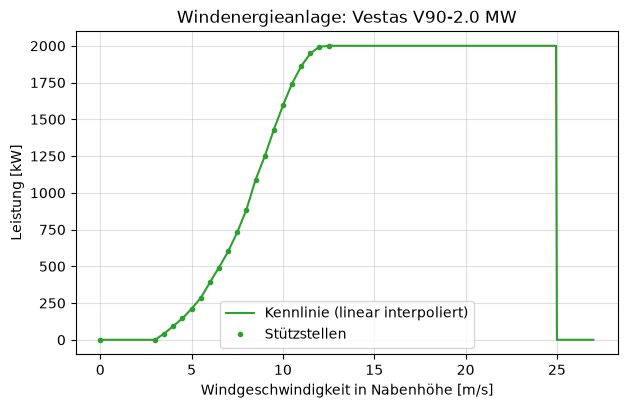

In [6]:
wt.plot_wind_curve()
plt.show()

### 1.3 PV-Anlage (Trina Solar Vertex S+ 460 W)

**Moduldaten:** Trina Solar Vertex S+ TSM-NEG9RC.27, bifaziales Glas-Glas-Modul (n-Typ, i-TOPCon), 144 Halbzellen, 1762 × 1134 mm (2,0 m²).

| Kenngröße | Wert | Quelle |
|---|---|---|
| Nennleistung P_STC (1000 W/m², 25 °C Zelltemperatur) | 460 W | [10] |
| Modulwirkungsgrad | 23,0 % | [10] |
| Temperaturkoeffizient von P_max (γ) | −0,29 %/K | [11] |
| NOCT (800 W/m², 20 °C Luft, 1 m/s Wind) | 43 °C | [11] |

Das Datenblatt [11] listet die Leistungsklassen 425–450 W; die Temperaturkennwerte gelten für die gesamte Modellfamilie und werden für die 460-W-Klasse übernommen.

**Umrechnung Einstrahlung → Leistung:**

1. *Einstrahlung auf die Modulebene:* Die API liefert direkt die Globalstrahlung auf die geneigte Fläche G (35°, Süd), sodass keine eigene Umrechnung von horizontaler auf geneigte Fläche nötig ist [6].
2. *Zelltemperatur* nach dem NOCT-Modell [12]:

   T_Zelle = T_Luft + (NOCT − 20 °C) / (800 W/m²) · G

3. *Leistung:* Die Modulleistung ist näherungsweise proportional zur Einstrahlung und nimmt mit steigender Zelltemperatur linear ab [12]:

   P_AC = P_STC · (G / 1000 W/m²) · [1 + γ · (T_Zelle − 25 °C)] · η_System

   mit η_System = 0,86 für Verluste in Wechselrichter, Leitungen, durch Verschmutzung und Fehlanpassung (Annahme; die Temperaturverluste sind bereits im Term mit γ enthalten).

**Beispiel:** Bei G = 1000 W/m² und 25 °C Lufttemperatur ist T_Zelle ≈ 53,8 °C und P_AC ≈ 363 W je Modul (0,79 kW/kWp).

**Vereinfachungen:** kein bifazialer Mehrertrag von der Rückseite, keine Verschattung, kein verändertes Verhalten bei schwacher Einstrahlung, keine Leistungsbegrenzung durch den Wechselrichter.

**Normierung:** Die Leistung wird je Modul (`pv_module_w`) und je kWp installierter Leistung (`pv_kw_per_kwp`) gespeichert. Eine Anlage mit z. B. 22 Modulen hat 22 × 0,46 kW = 10,12 kWp; ihre Leistung ist `pv_kw_per_kwp` × 10,12 kW.

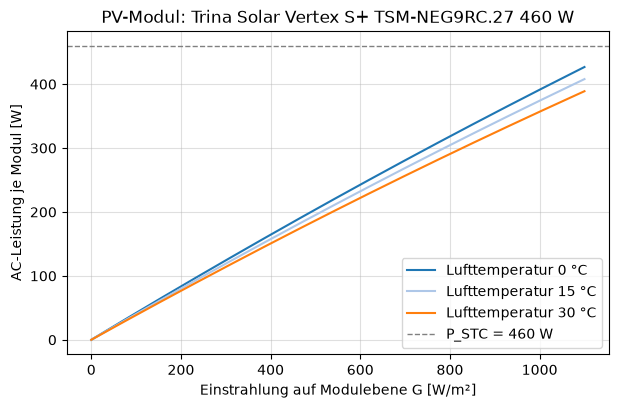

In [7]:
wt.plot_pv_curve()
plt.show()

### 1.4 Wetterdaten (Open-Meteo)

**Herkunft:** Die Wetterdaten stammen aus der *Historical Weather API* von Open-Meteo [4], [6]. Sie beruht auf Reanalyse-Datensätzen, in denen Messungen von Wetterstationen, Satelliten, Flugzeugen und Bojen mit einem numerischen Wettermodell zu einem lückenlosen Gitterdatensatz verbunden werden, unter anderem ERA5 des europäischen Wetterdienstes ECMWF [5].

**Abruf:** Standort 51,2° N, 7,34° E (Bergisches Land, NRW), Jahr 2025, stündliche Werte:

| Variable | Einheit | Bedeutung | Verwendung |
|---|---|---|---|
| `global_tilted_irradiance` | W/m² | Globalstrahlung auf eine geneigte Fläche (35° Neigung, Ausrichtung Süd), Mittel der vorangegangenen Stunde | PV |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe, Momentanwert | PV (Zelltemperatur) |
| `wind_speed_100m` | m/s | Windgeschwindigkeit in 100 m Höhe, Momentanwert | Wind |
| `shortwave_radiation` | W/m² | Globalstrahlung auf die horizontale Fläche | nur zur Information |

**Aufbereitung:**

1. Die API liefert Zeitstempel in UTC. Sie werden in lokale Zeit (Europe/Berlin) umgerechnet. Die Einstrahlung bezieht sich auf die vorangegangene Stunde und wird um eine Stunde verschoben, sodass alle Zeitstempel den Beginn der Stunde bezeichnen [6].
2. Aus den Wetterdaten wird über die Kennlinien die Leistung von PV und Wind berechnet (siehe unten).
3. **Typische Woche:** Für jeden Monat werden alle Wochen (Mo–So) betrachtet, die vollständig im Monat liegen, keine Zeitumstellung und keinen Feiertag enthalten. Gewählt wird die Woche, deren mittlere PV-Leistung und mittlere Windleistung zusammen am wenigsten vom Monatsmittel abweichen (Summe der relativen Abweichungen). So wird weder eine außergewöhnlich sonnige noch eine windstille Woche ausgewählt.
4. Ergebnis und Rohdaten werden als CSV gespeichert (`data/weather_weeks_2025.csv`, `data/weather_raw_2025.csv`).

**Tabelle der typischen Wochen** (erste Zeilen der Datei `weather_weeks_2025.csv`):

In [8]:
weather_table = pd.read_csv(WEATHER_FILE, index_col="time", parse_dates=True)
print(f"{len(weather_table)} Zeilen (12 Wochen × 168 Stunden), {weather_table.shape[1]} Spalten")
weather_table.head(10)

2016 Zeilen (12 Wochen × 168 Stunden), 10 Spalten


,month,hour_of_week,temperature_2m,global_tilted_irradiance,wind_speed_100m,wind_speed_hub,pv_module_w,pv_kw_per_kwp,wind_kw,wind_pu
time,,,,,,,,,,
2025-01-06 00:00:00,JANUARY,0,7.05,0.0000,11.7466,11.8288,0.0000,0.0000,1977.8195,0.9889
2025-01-06 01:00:00,JANUARY,1,7.15,0.0000,12.0354,12.1195,0.0000,0.0000,1994.9019,0.9975
2025-01-06 02:00:00,JANUARY,2,8.70,0.0000,11.6010,11.6821,0.0000,0.0000,1964.5629,0.9823
2025-01-06 03:00:00,JANUARY,3,8.55,0.0000,11.2695,11.3484,0.0000,0.0000,1921.7454,0.9609
2025-01-06 04:00:00,JANUARY,4,8.40,0.0000,11.6813,11.7630,0.0000,0.0000,1971.8745,0.9859
2025-01-06 05:00:00,JANUARY,5,8.20,0.0000,11.5412,11.6220,0.0000,0.0000,1959.1246,0.9796
2025-01-06 06:00:00,JANUARY,6,8.10,0.0000,12.6646,12.7532,0.0000,0.0000,2000.0000,1.0000
2025-01-06 07:00:00,JANUARY,7,8.15,0.0000,13.1477,13.2397,0.0000,0.0000,2000.0000,1.0000
2025-01-06 08:00:00,JANUARY,8,8.30,0.0000,13.6401,13.7355,0.0000,0.0000,2000.0000,1.0000


| Spalte | Einheit | Bedeutung |
|---|---|---|
| `time` | – | Beginn der Stunde, lokale Zeit (MEZ/MESZ) |
| `month`, `hour_of_week` | – | Monat (Enum `Month`), Stunde der Woche 0 … 167 (Mo 00:00 = 0) |
| `temperature_2m` | °C | Lufttemperatur in 2 m Höhe |
| `global_tilted_irradiance` | W/m² | Einstrahlung auf die Modulebene (35°, Süd) |
| `wind_speed_100m`, `wind_speed_hub` | m/s | Windgeschwindigkeit in 100 m bzw. Nabenhöhe (105 m) |
| `pv_module_w` | W | AC-Leistung eines PV-Moduls (460 W) |
| `pv_kw_per_kwp` | kW/kWp | AC-Leistung je kWp |
| `wind_kw` | kW | Leistung der V90-2.0 MW |
| `wind_pu` | – | Leistung bezogen auf die Nennleistung |

In [9]:
overview = pd.DataFrame({
    "Woche ab": [df.index[0].strftime("%a %d.%m.%Y") for df in WEATHER.values()],
    "T_Luft Mittel [°C]": [df["temperature_2m"].mean() for df in WEATHER.values()],
    "G_Modul max [W/m²]": [df["global_tilted_irradiance"].max() for df in WEATHER.values()],
    "Wind Nabe Mittel [m/s]": [df["wind_speed_hub"].mean() for df in WEATHER.values()],
    "PV-Modul Energie [kWh/Woche]": [df["pv_module_w"].sum() / 1000 for df in WEATHER.values()],
    "WEA Energie [MWh/Woche]": [df["wind_kw"].sum() / 1000 for df in WEATHER.values()],
}, index=[m.label for m in WEATHER])
overview.round(1)

,Woche ab,T_Luft Mittel [°C],G_Modul max [W/m²],Wind Nabe Mittel [m/s],PV-Modul Energie [kWh/Woche],WEA Energie [MWh/Woche]
Januar,Mon 06.01.2025,0.6,498.5,7.9,2.7,154.7
Februar,Mon 03.02.2025,1.2,737.4,6.3,6.2,100.9
März,Mon 03.03.2025,7.9,912.4,5.1,16.2,64.8
April,Mon 07.04.2025,9.7,993.7,5.2,17.1,59.7
Mai,Mon 19.05.2025,12.2,1041.2,6.0,14.5,86.3
Juni,Mon 09.06.2025,17.3,994.3,6.3,16.0,99.1
Juli,Mon 21.07.2025,17.5,882.4,4.7,13.6,45.6
August,Mon 04.08.2025,17.7,979.5,5.3,15.7,59.6
September,Mon 08.09.2025,13.7,866.6,6.8,10.5,116.1
Oktober,Mon 13.10.2025,10.0,697.3,4.6,6.7,48.5


**Wetterdiagramme:** Für jeden Monat zeigt ein zweiteiliges Diagramm die typische Woche:

- **oben:** Windgeschwindigkeit in Nabenhöhe [m/s], Lufttemperatur [°C] und Einstrahlung auf die Modulebene [100 W/m²]
- **unten:** Leistung der Windenergieanlage [MW] und eines PV-Moduls [100 W]

Die Einstrahlung und die PV-Leistung sind so skaliert, dass alle Größen im selben Zahlenbereich liegen: Ein Wert von 2 im unteren Diagramm entspricht 2 MW der Windenergieanlage bzw. 200 W des PV-Moduls, ein Wert von 8 im oberen Diagramm entspricht 800 W/m² Einstrahlung.

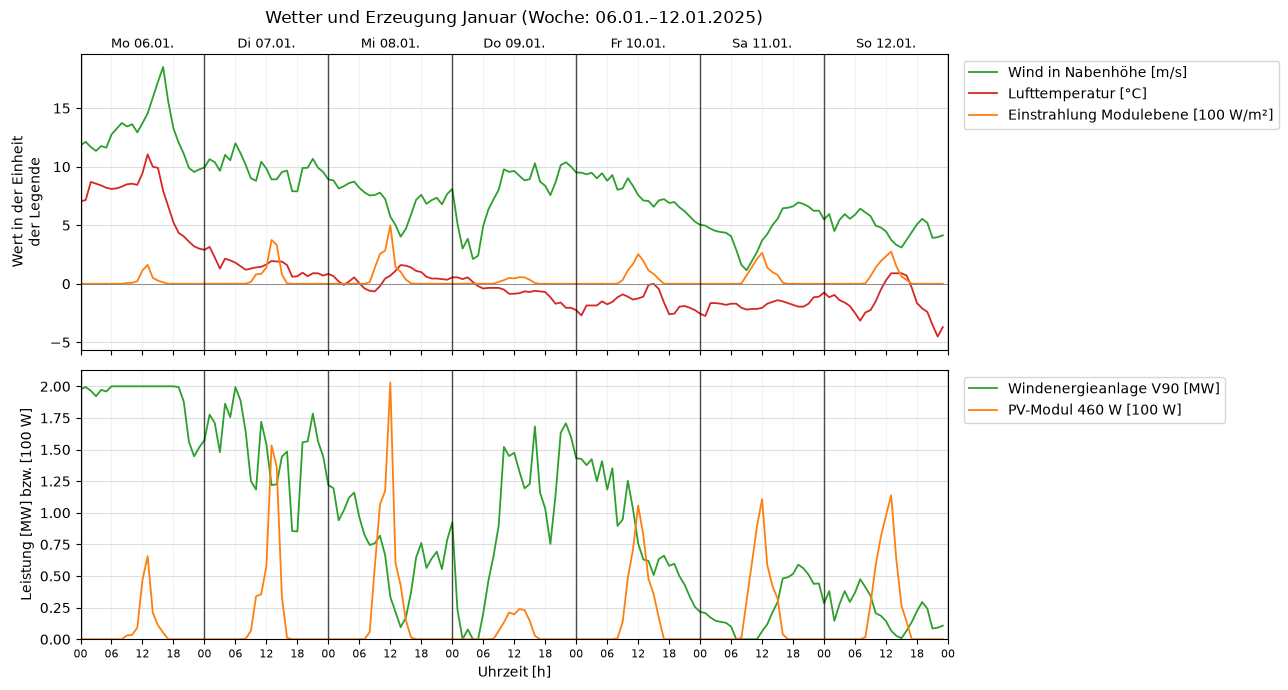

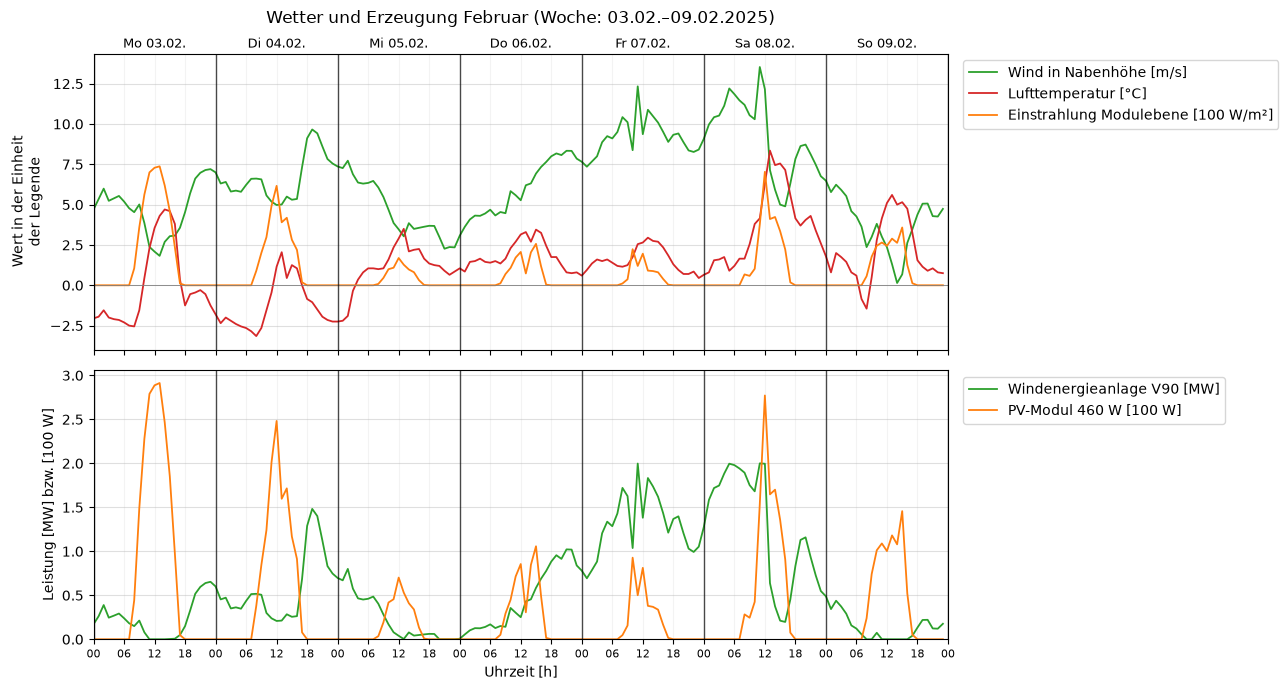

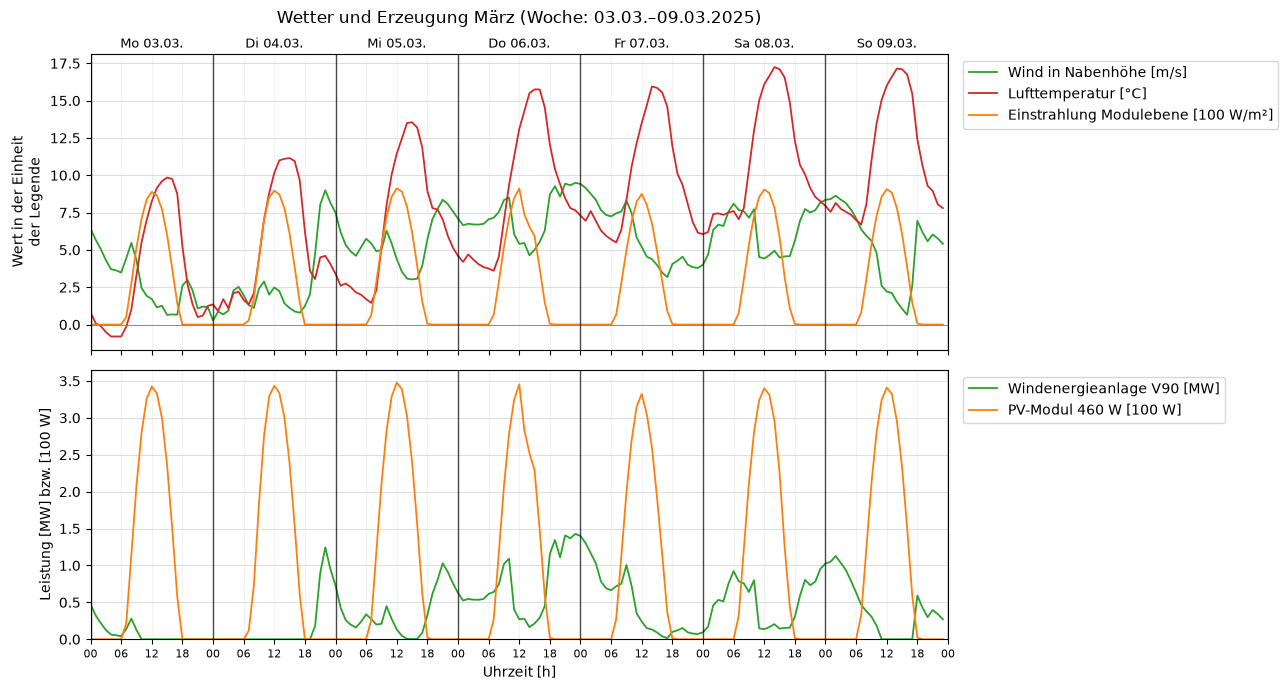

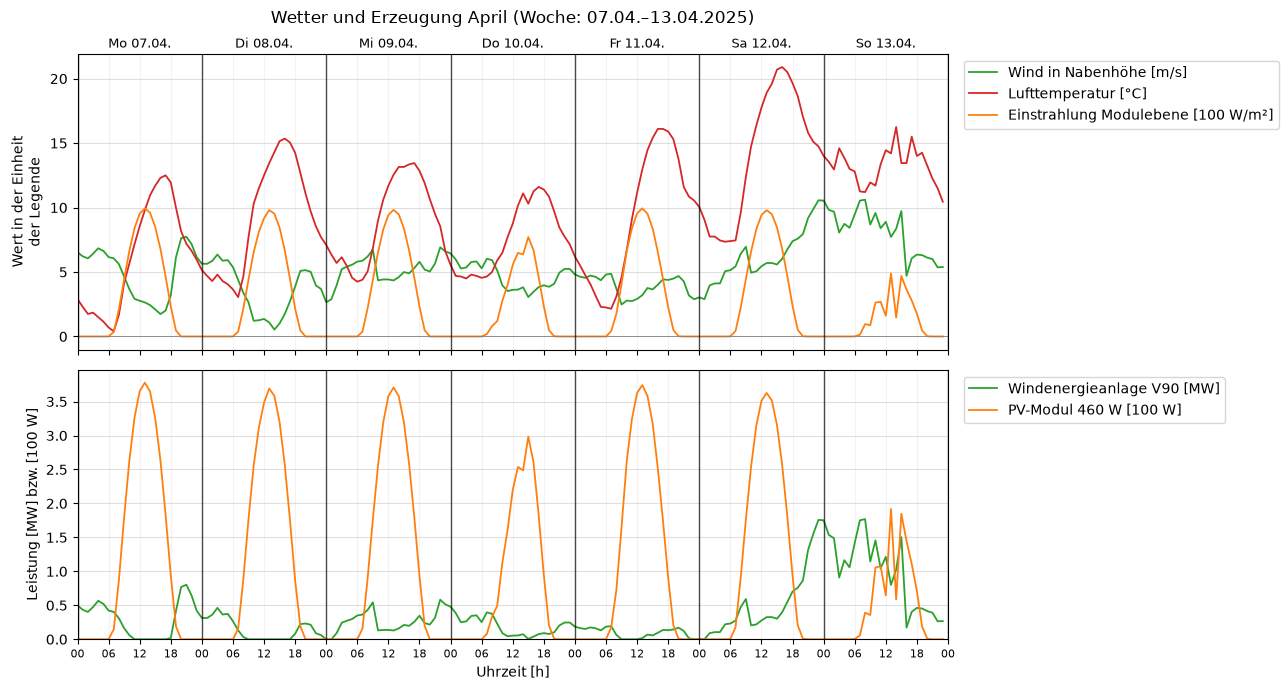

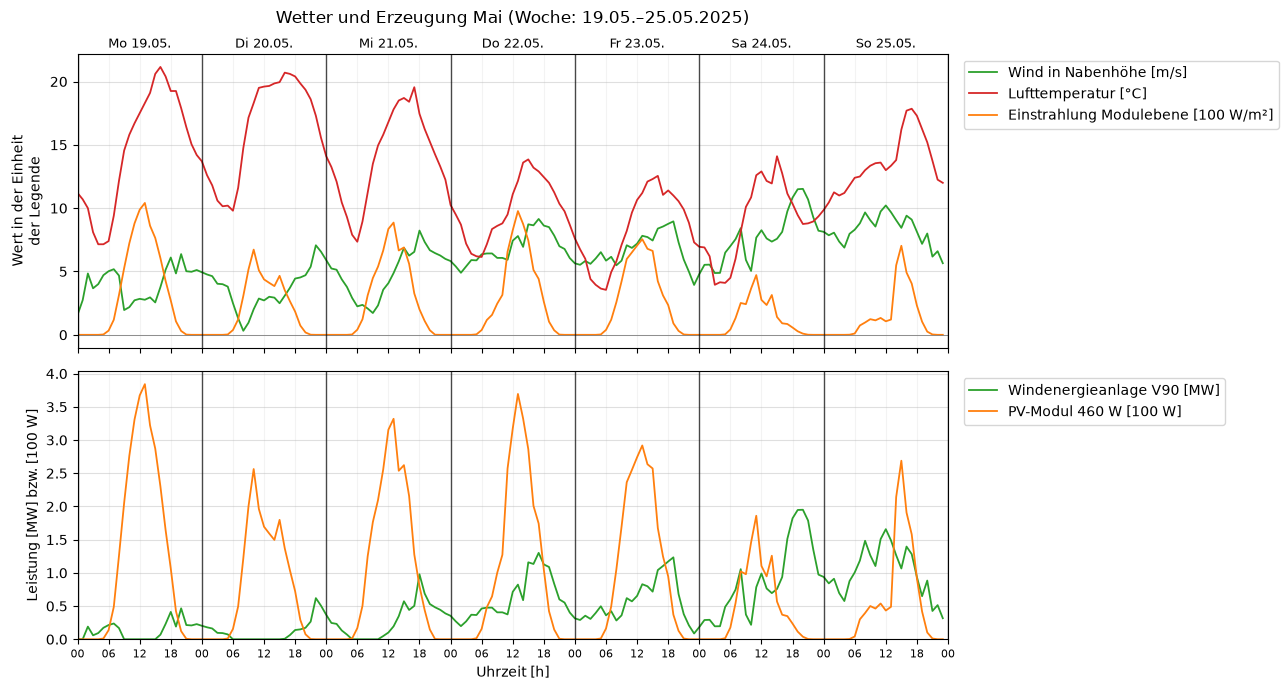

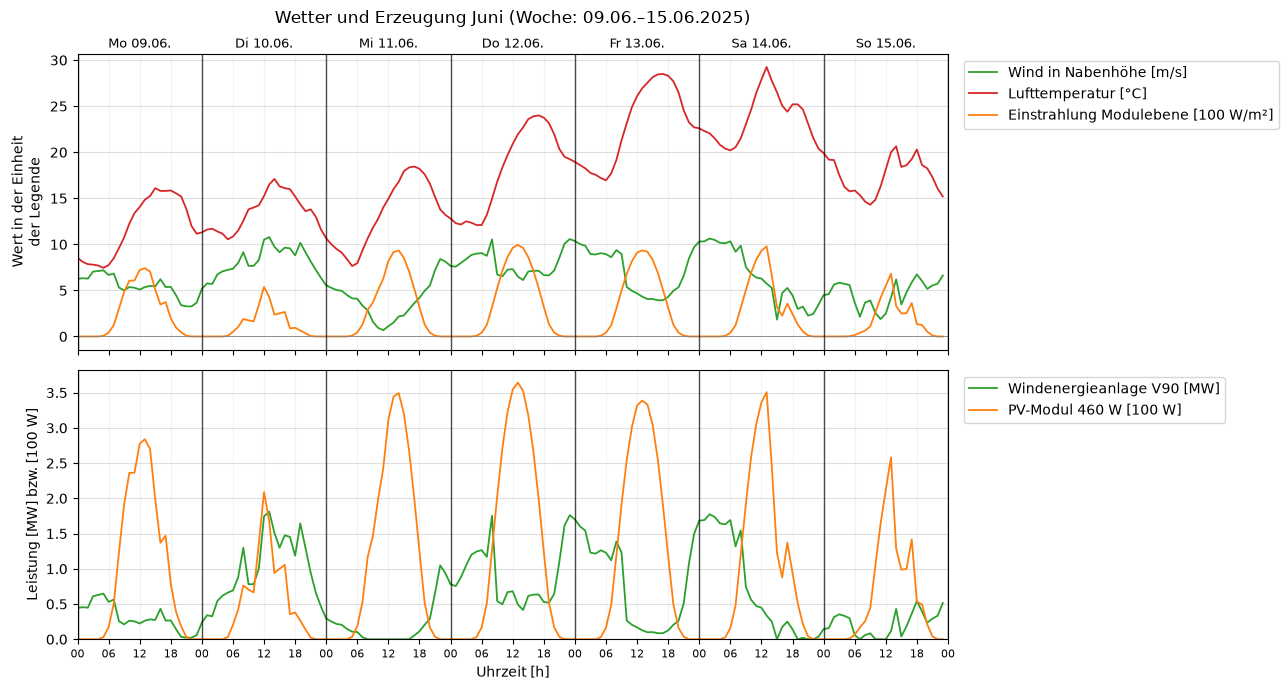

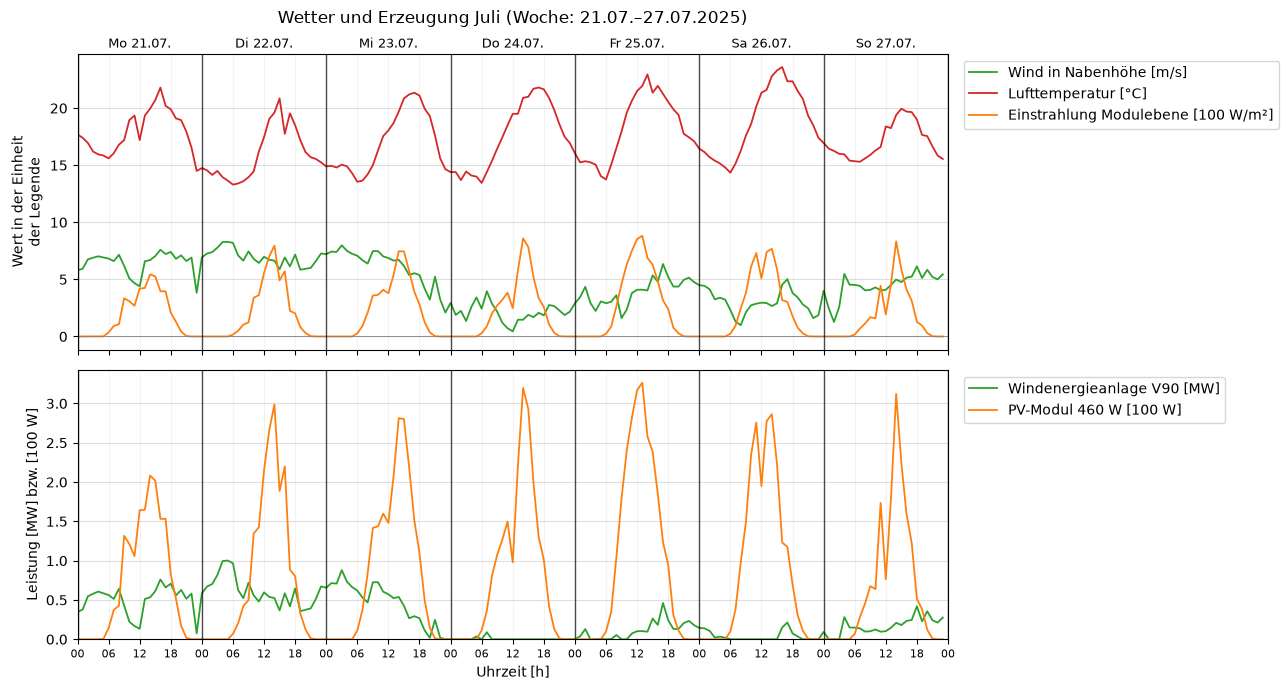

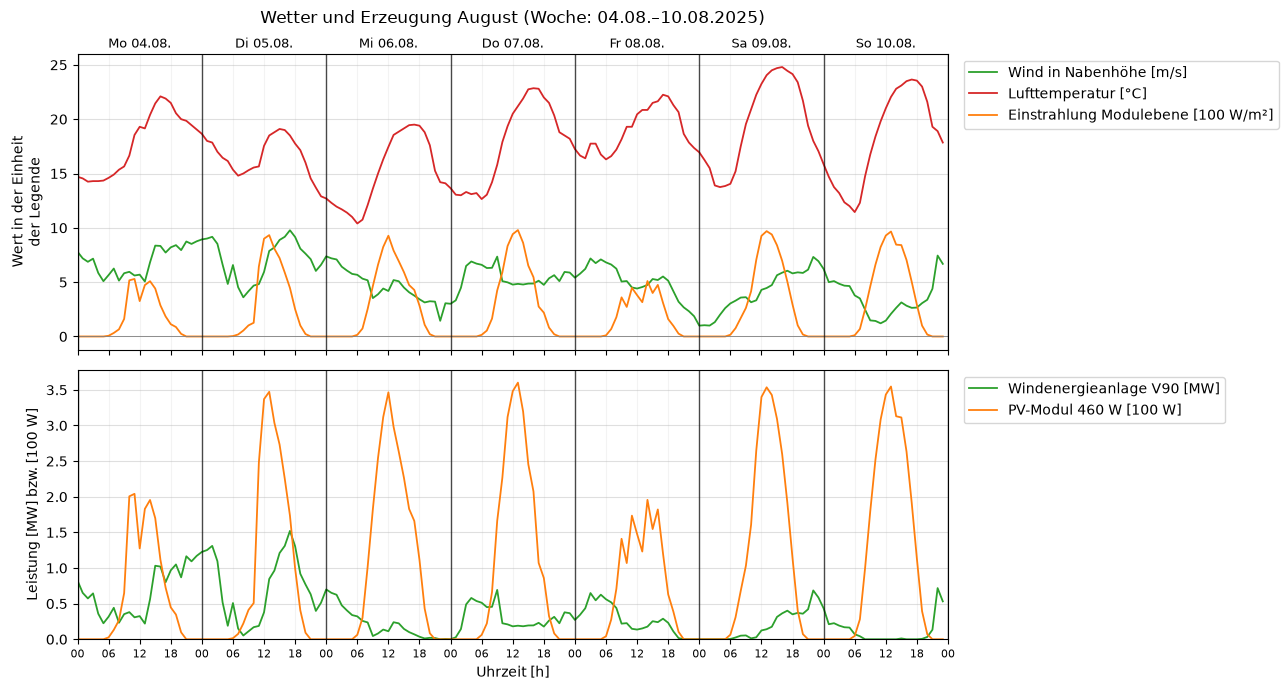

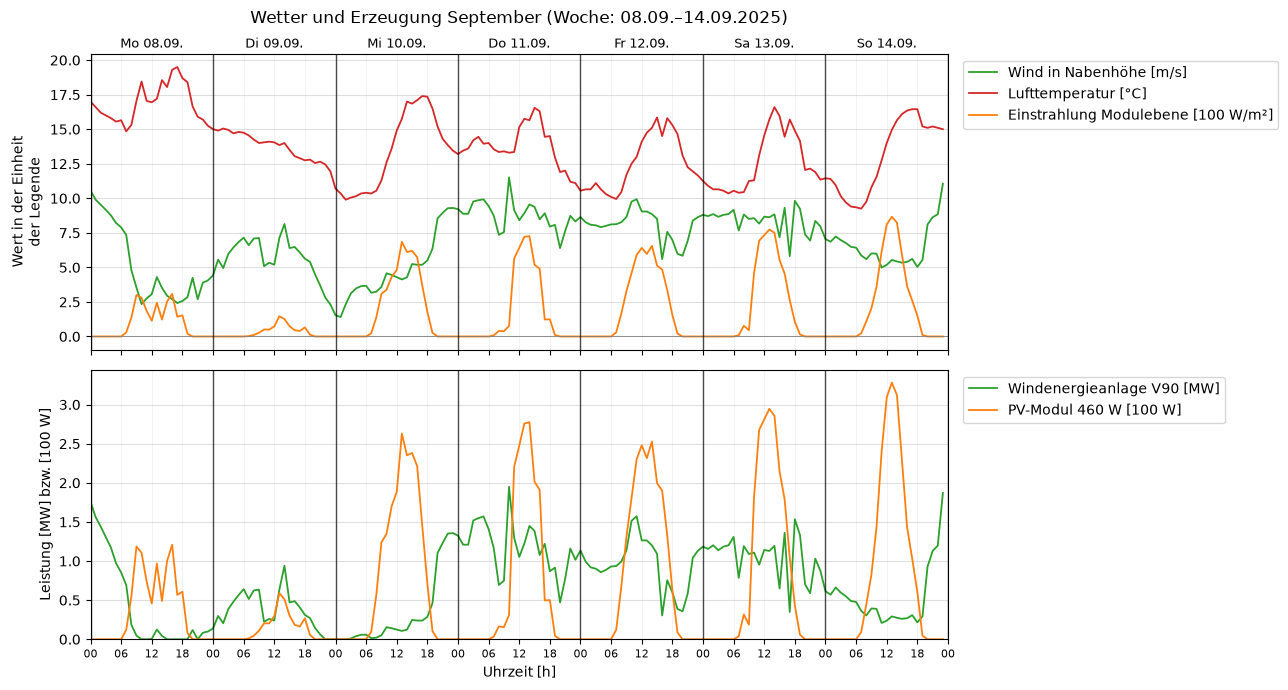

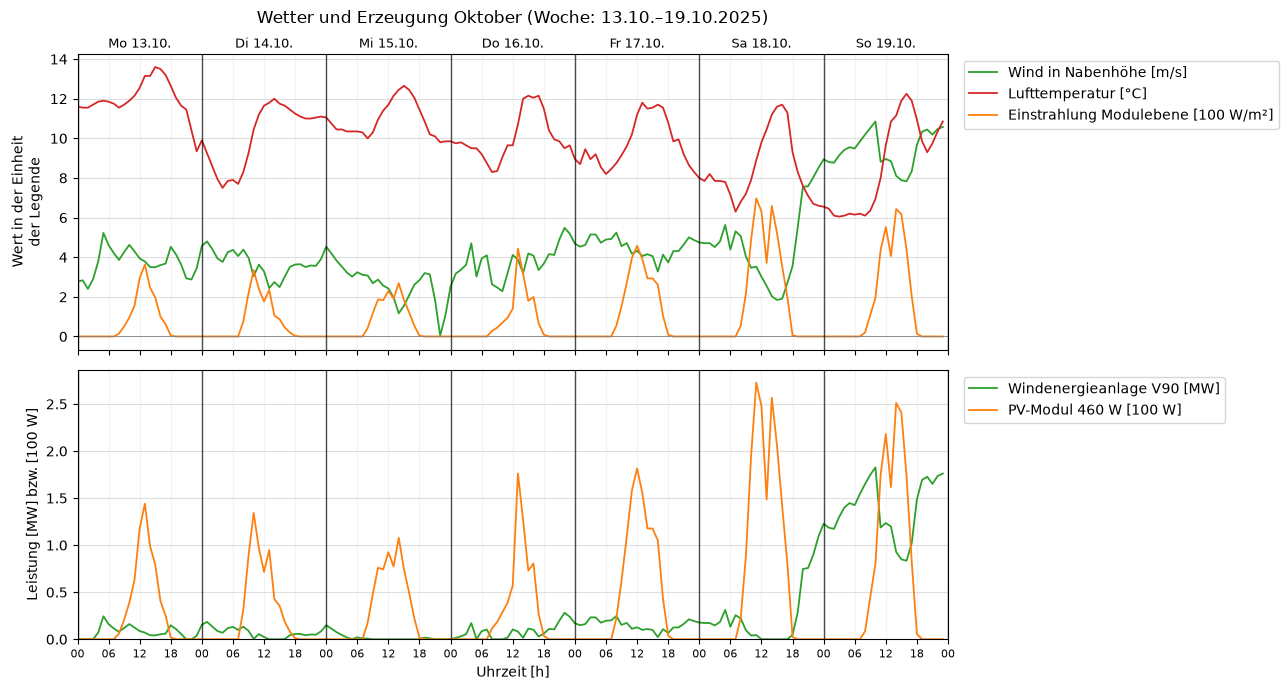

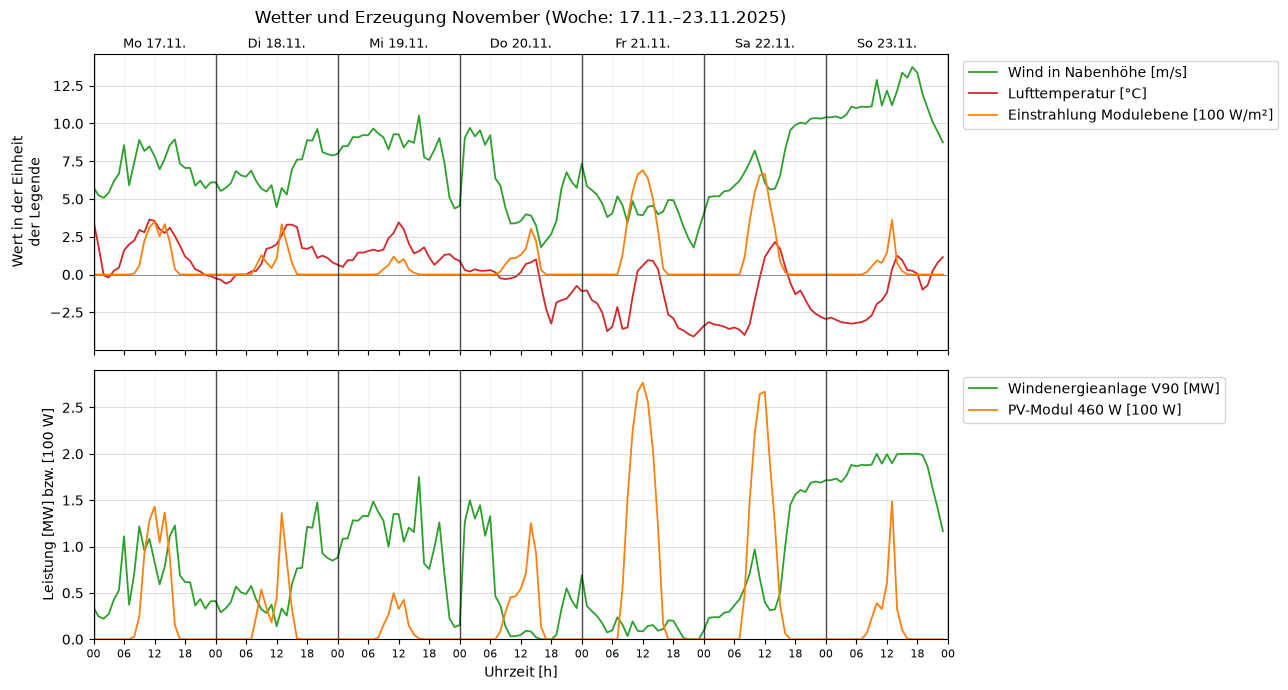

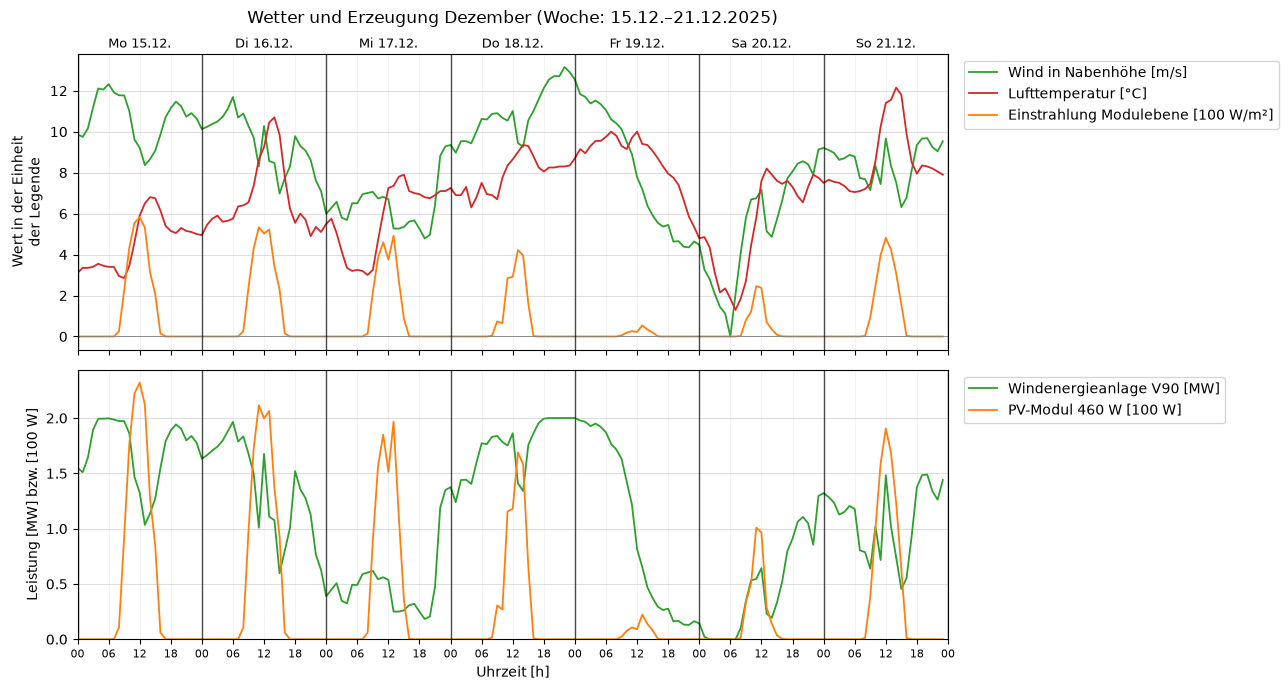

In [10]:
for month, w in WEATHER.items():
    plots.plot_weather_week(w, f"Wetter und Erzeugung {month.label} "
                               f"(Woche: {w.index[0]:%d.%m.}–{w.index[-1]:%d.%m.%Y})")
    plt.show()

### Quellen zu den Daten

[1] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Hinweise zu den aktualisierten Standardlastprofilen Strom“, Anwendungshilfe, Berlin, 17.03.2025, S. 3–4. Online: https://bdew.de/media/documents/2025-03-17_AWH_Aktualisierte_SLP_Strom_2025_Ver%C3%B6ffentlichung.pdf

[2] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Repräsentative Profile BDEW H25, G25, L25, P25, S25 – Veröffentlichung“, Datensatz (CSV, Profil Haushalte), Berlin, 2025.

[3] BDEW Bundesverband der Energie- und Wasserwirtschaft e. V., „Anwendung der Repräsentativen VDEW-Lastprofile step-by-step“, Berlin, 2000, S. 18 f. Online: https://www.bdew.de/media/documents/2000131_Anwendung-repraesentativen_Lastprofile-Step-by-step.pdf

[4] P. Zippenfenig, „Open-Meteo.com Weather API“, Zenodo, 2023, doi: 10.5281/ZENODO.7970649.

[5] H. Hersbach et al., „The ERA5 global reanalysis“, Quarterly Journal of the Royal Meteorological Society, Bd. 146, Nr. 730, S. 1999–2049, 2020, doi: 10.1002/qj.3803.

[6] Open-Meteo, „Historical Weather API – Documentation“. Online: https://open-meteo.com/en/docs/historical-weather-api (Abruf: 14.10.2026).

[7] wind-turbine-models.com, „Vestas V90“. Online: https://www.wind-turbine-models.com/turbines/16-vestas-v90 (Abruf: 14.10.2026).

[8] windpowerlib, Version 0.2.2, Turbinendatenbank der Open Energy Database (Datei `oedb/power_curves.csv`, Eintrag „V90/2000“). Online: https://github.com/wind-python/windpowerlib

[9] E. Hau, *Windkraftanlagen: Grundlagen, Technik, Einsatz, Wirtschaftlichkeit*, 6. Aufl. Berlin, Heidelberg: Springer Vieweg, 2016.

[10] Trina Solar, „Vertex S+ NEG9RC.27“, Produktseite. Online: https://www.trinasolar.com/de/NEG9RC.27/ (Abruf: 14.10.2026).

[11] Trina Solar, „Vertex S+ – Bifaziales Doppelglas N-Typ i-TOPCon Modul, TSM-NEG9RC.27“, Datenblatt, Version TSM_DE_2024_B, 2024. Online: https://www-cdn.trinasolar.com/wwwstorage/sites/8/250227_Datasheet_VertexS_NEG9RC.27_DE_2024_B_web.pdf

[12] J. A. Duffie und W. A. Beckman, *Solar Engineering of Thermal Processes*, 4. Aufl. Hoboken, NJ: Wiley, 2013.

*Bei [3], [9] und [12] die verwendeten Seiten bzw. Kapitel anhand der eigenen Ausgabe ergänzen bzw. prüfen.*

## 2 Netzaufbau: CIGRE-Mittelspannungsnetz

Das CIGRE-MV-Netz ist ein Benchmarknetz der CIGRE Task Force C6.04.02 zur Untersuchung der Integration erneuerbarer und dezentraler Erzeugung [13]. Es bildet ein europäisches Mittelspannungsnetz (20 kV) ab, das aus einem 110-kV-Netz über zwei Umspanntransformatoren versorgt wird. In pandapower ist es als `pn.create_cigre_network_mv()` hinterlegt [14].

pandapower stellt das Netz in drei Varianten bereit:

| `with_der` | dezentrale Erzeugung |
|---|---|
| `False` | keine |
| `"pv_wind"` | 8 PV-Anlagen und 1 Windenergieanlage |
| `"all"` | zusätzlich Batteriespeicher, Brennstoffzellen, Mikro-KWK u. a. |

Verwendet wird die Variante **`"pv_wind"`**. Sie enthält genau die beiden Erzeugungsarten, für die in Abschnitt 1 Zeitreihen aufbereitet wurden. Die PV-Anlagen und die Windenergieanlage können damit später mit den saisonalen Wetterprofilen betrieben werden.

In [11]:
net = pn.create_cigre_network_mv(with_der="pv_wind")
net

This pandapower network includes the following parameter tables:
   - bus (15 elements)
   - load (18 elements)
   - sgen (9 elements)
   - switch (8 elements)
   - ext_grid (1 element)
   - line (15 elements)
   - trafo (2 elements)

### 2.1 Netzplan

![CIGRE-MV-Netz mit PV und Wind](cigre_network_mv_der.png)

*Bild: Netzplan des CIGRE-MV-Netzes mit PV- und Windanlagen (`with_der="pv_wind"`) aus der pandapower-Dokumentation [14], nach dem Benchmark-Netz der CIGRE Task Force C6.04.02 [13]. Quelle der Bilddatei: pandapower-Repository, `doc/pics/networks/cigre/cigre_network_mv_der.pnp` (BSD-3-Clause-Lizenz).*

Hinweis: Im Original-Benchmark [13] ist das vorgelagerte Netz mit 220 kV angegeben und es sind zusätzlich Batteriespeicher, Brennstoffzellen und BHKW enthalten. pandapower nimmt mangels Daten für einen 220/20-kV-Transformator 110 kV an und berücksichtigt in der Variante `pv_wind` nur die PV-Anlagen und die Windenergieanlage. Der Netzplan oben entspricht deshalb genau dem hier verwendeten Modell.

**Aufbau:**

- **Einspeisung:** Das externe Netz (110 kV, Slack mit 1,03 pu) speist an Bus 0. Zwei Transformatoren 110/20 kV mit je 25 MVA versorgen die beiden Abgänge.
- **Abgang 1 (Bus 1 bis Bus 11):** Kabelnetz in Ringstruktur mit Abzweig. Die Ringe sind über die offenen Trennschalter **S2** (Leitung 6-7) und **S3** (Leitung 11-4) aufgetrennt, sodass das Netz im Normalbetrieb **strahlenförmig** betrieben wird.
- **Abgang 2 (Bus 12 bis Bus 14):** Freileitungen.
- **Kupplung der Abgänge:** Der offene Trennschalter **S1** (Leitung 14-8) verbindet Abgang 2 mit Abgang 1. Durch Schließen von S1, S2 oder S3 kann bei Störungen umgeschaltet werden (Wiederversorgung).
- **Dezentrale Erzeugung:** acht PV-Anlagen mit 10–40 kW (zusammen 0,21 MW) an den Bussen 3, 4, 5, 6, 8, 9, 10 und 11 sowie eine Windenergieanlage mit 1,5 MW an Bus 7.
- **Lasten:** An den meisten Bussen hängen Wohngebiete (R, *residential*) und/oder Gewerbe/Industrie (CI, *commercial/industrial*). Die großen Lasten an Bus 1 und Bus 12 liegen direkt an den Unterspannungssammelschienen der Transformatoren und bilden die Belastung durch weitere, nicht einzeln modellierte Abgänge nach.

### 2.2 Komponenten

In [12]:
plots.component_overview(net)

,Element,Anzahl
Tabelle,,
net.bus,Sammelschienen / Knoten,15
net.line,Leitungen,15
net.trafo,Zweiwicklungstransformatoren,2
net.switch,Schalter,8
net.ext_grid,externes Netz (Slack),1
net.load,Lasten,18
net.sgen,statische Erzeuger,9


#### Sammelschienen (`net.bus`)

In [13]:
net.bus[["name", "vn_kv", "type", "zone", "in_service"]]

,name,vn_kv,type,zone,in_service
0,Bus 0,110.0,b,CIGRE_MV,True
1,Bus 1,20.0,b,CIGRE_MV,True
2,Bus 2,20.0,b,CIGRE_MV,True
3,Bus 3,20.0,b,CIGRE_MV,True
4,Bus 4,20.0,b,CIGRE_MV,True
5,Bus 5,20.0,b,CIGRE_MV,True
6,Bus 6,20.0,b,CIGRE_MV,True
7,Bus 7,20.0,b,CIGRE_MV,True
8,Bus 8,20.0,b,CIGRE_MV,True
9,Bus 9,20.0,b,CIGRE_MV,True


#### Transformatoren (`net.trafo`)

In [14]:
net.trafo[["name", "hv_bus", "lv_bus", "sn_mva", "vn_hv_kv", "vn_lv_kv", "vk_percent", "vkr_percent",
           "pfe_kw", "i0_percent", "shift_degree", "tap_side", "tap_pos"]]

,name,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,i0_percent,shift_degree,tap_side,tap_pos
0,Trafo 0-1,0,1,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,None,NaN
1,Trafo 0-12,0,12,25.0,110.0,20.0,12.00107,0.16,0.0,0.0,30.0,None,NaN


Die Transformatoren haben im pandapower-Modell **keinen Stufenschalter** (`tap_side` und `tap_pos` leer). Die Spannung im 20-kV-Netz wird allein durch die Slack-Spannung von 1,03 pu und die Spannungsfälle bestimmt.

#### Leitungen (`net.line`)

In [15]:
net.line[["name", "from_bus", "to_bus", "length_km", "std_type", "type",
          "r_ohm_per_km", "x_ohm_per_km", "c_nf_per_km", "max_i_ka"]]

,name,from_bus,to_bus,length_km,std_type,type,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka
0,Line 1-2,1,2,2.82,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
1,Line 2-3,2,3,4.42,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
2,Line 3-4,3,4,0.61,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
3,Line 4-5,4,5,0.56,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
4,Line 5-6,5,6,1.54,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
5,Line 7-8,7,8,1.67,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
6,Line 8-9,8,9,0.32,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
7,Line 9-10,9,10,0.77,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
8,Line 10-11,10,11,0.33,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145
9,Line 3-8,3,8,1.30,CABLE_CIGRE_MV,cs,0.501,0.716,151.17490,0.145


In [16]:
(net.line.groupby("std_type")
    .agg(Anzahl=("length_km", "size"), Gesamtlänge_km=("length_km", "sum"),
         Typ=("type", "first"), r_ohm_per_km=("r_ohm_per_km", "first"),
         x_ohm_per_km=("x_ohm_per_km", "first"), c_nf_per_km=("c_nf_per_km", "first"),
         max_i_ka=("max_i_ka", "first")))

,Anzahl,Gesamtlänge_km,Typ,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,max_i_ka
std_type,,,,,,,
CABLE_CIGRE_MV,12,15.07,cs,0.501,0.716,151.17490,0.145
OHL_CIGRE_MV,3,9.88,ol,0.510,0.366,10.09679,0.195


Es gibt zwei Leitungstypen: Kabel (`cs`, Abgang 1 und Kupplungen) und Freileitungen (`ol`, Abgang 2). Bei den Kabeln ist die Reaktanz größer als der Widerstand (X/R ≈ 1,4), anders als im Niederspannungsnetz aus Task 1 und 2. Die Kapazität der Kabel ist etwa 15-mal so groß wie die der Freileitungen.

#### Schalter (`net.switch`)

In [17]:
sw = net.switch.copy()
sw["Leitung/Trafo"] = [net.line.at[e, "name"] if et == "l" else net.trafo.at[e, "name"]
                       for e, et in zip(sw.element, sw.et)]
sw["an Bus"] = net.bus.loc[sw.bus, "name"].to_numpy()
sw[["name", "type", "closed", "et", "Leitung/Trafo", "an Bus"]]

,name,type,closed,et,Leitung/Trafo,an Bus
0,None,LBS,True,l,Line 6-7,Bus 6
1,S2,LBS,False,l,Line 6-7,Bus 7
2,S3,LBS,False,l,Line 11-4,Bus 4
3,None,LBS,True,l,Line 11-4,Bus 11
4,S1,LBS,False,l,Line 14-8,Bus 8
5,None,LBS,True,l,Line 14-8,Bus 14
6,None,CB,True,t,Trafo 0-1,Bus 0
7,None,CB,True,t,Trafo 0-12,Bus 0


| Typ | Bedeutung |
|---|---|
| `LBS` | Lasttrennschalter (*load break switch*) an den Leitungsenden; offen: S1, S2, S3 als Trennstellen |
| `CB` | Leistungsschalter (*circuit breaker*) an der Oberspannungsseite der Transformatoren |
| `et = "l"` / `"t"` | Schalter an einer Leitung bzw. einem Transformator |

#### Externes Netz (`net.ext_grid`)

In [18]:
net.ext_grid[["bus", "vm_pu", "va_degree", "s_sc_max_mva", "rx_max"]]

,bus,vm_pu,va_degree,s_sc_max_mva,rx_max
0,0,1.03,0.0,5000.0,0.1


#### Lasten (`net.load`)

In [19]:
loads = net.load[["name", "bus", "p_mw", "q_mvar", "sn_mva"]].copy()
loads["Art"] = np.where(loads.name.str.contains("CI"), "Gewerbe/Industrie", "Wohngebiet")
loads["cos φ"] = loads.p_mw / np.hypot(loads.p_mw, loads.q_mvar)
loads.round(3)

,name,bus,p_mw,q_mvar,sn_mva,Art,cos φ
0,Load R1,1,14.994,3.045,15.300,Wohngebiet,0.98
1,Load R3,3,0.276,0.069,0.285,Wohngebiet,0.97
2,Load R4,4,0.432,0.108,0.445,Wohngebiet,0.97
3,Load R5,5,0.728,0.182,0.750,Wohngebiet,0.97
4,Load R6,6,0.548,0.137,0.565,Wohngebiet,0.97
5,Load R8,8,0.587,0.147,0.605,Wohngebiet,0.97
6,Load R10,10,0.475,0.119,0.490,Wohngebiet,0.97
7,Load R11,11,0.330,0.083,0.340,Wohngebiet,0.97
8,Load R12,12,14.994,3.045,15.300,Wohngebiet,0.98
9,Load R14,14,0.209,0.052,0.215,Wohngebiet,0.97


In [20]:
summary = loads.groupby("Art").agg(Anzahl=("p_mw", "size"), P_MW=("p_mw", "sum"), Q_Mvar=("q_mvar", "sum"))
summary.loc["Summe"] = summary.sum()
summary.round(2)

,Anzahl,P_MW,Q_Mvar
Art,,,
Gewerbe/Industrie,8.0,11.17,4.05
Wohngebiet,10.0,33.57,6.99
Summe,18.0,44.74,11.04


#### Dezentrale Erzeugung (`net.sgen`)

In [21]:
gens = net.sgen[["name", "bus", "type", "p_mw", "q_mvar", "sn_mva", "in_service"]].copy()
gens["Art"] = gens["type"].map({"PV": "Photovoltaik", "WP": "Windenergie"})
gens

,name,bus,type,p_mw,q_mvar,sn_mva,in_service,Art
0,PV 3,3,PV,0.02,0.0,0.02,True,Photovoltaik
1,PV 4,4,PV,0.02,0.0,0.02,True,Photovoltaik
2,PV 5,5,PV,0.03,0.0,0.03,True,Photovoltaik
3,PV 6,6,PV,0.03,0.0,0.03,True,Photovoltaik
4,PV 8,8,PV,0.03,0.0,0.03,True,Photovoltaik
5,PV 9,9,PV,0.03,0.0,0.03,True,Photovoltaik
6,PV 10,10,PV,0.04,0.0,0.04,True,Photovoltaik
7,PV 11,11,PV,0.01,0.0,0.01,True,Photovoltaik
8,WKA 7,7,WP,1.50,0.0,1.50,True,Windenergie


In [22]:
gen_sum = gens.groupby("Art").agg(Anzahl=("p_mw", "size"), P_MW=("p_mw", "sum"))
gen_sum["Anteil an der Gesamtlast [%]"] = gen_sum.P_MW / net.load.p_mw.sum() * 100
gen_sum.round(3)

,Anzahl,P_MW,Anteil an der Gesamtlast [%]
Art,,,
Photovoltaik,8,0.21,0.469
Windenergie,1,1.50,3.353


Die Erzeugungsanlagen speisen mit cos φ = 1 (keine Blindleistung). Die angegebene Leistung `p_mw` ist ein fester Arbeitspunkt; für die saisonale Untersuchung wird sie später über die PV- und Windzeitreihen aus Abschnitt 1 vorgegeben. Mit zusammen 1,71 MW ist die installierte Erzeugung klein im Vergleich zur Gesamtlast von 44,7 MW, wirkt aber lokal: Die Windenergieanlage an Bus 7 speist in Abgang 1 ein, der im Netz ohne Erzeugung die niedrigsten Spannungen aufweist.

### Quellen zum Netz

[13] K. Strunz et al., „Benchmark Systems for Network Integration of Renewable and Distributed Energy Resources“, CIGRE Task Force C6.04.02, Technical Brochure 575, Paris: CIGRE, 2014.

[14] L. Thurner et al., „pandapower – An Open-Source Python Tool for Convenient Modeling, Analysis, and Optimization of Electric Power Systems“, IEEE Transactions on Power Systems, Bd. 33, Nr. 6, S. 6510–6521, Nov. 2018, doi: 10.1109/TPWRS.2018.2829021.

*Kapitel und Seiten von [13] anhand der verwendeten Ausgabe ergänzen.*

## 3 Lastfluss und Auswertung

Die Auswertung erfolgt in zwei Stufen:

1. **Statischer Lastfluss (Punkte 2 bis 4 des Arbeitsauftrags):** Das CIGRE-Netz wird mit den in [13] angegebenen Leistungen berechnet. Alle Lasten und Erzeuger arbeiten dabei gleichzeitig mit ihrer Bemessungsleistung. Das ist ein einzelner, sehr ungünstiger Betriebspunkt.
2. **Saisonale Simulation:** Lasten und Erzeuger folgen den BDEW-Lastprofilen und den Wetterdaten. Für jeden Monat wird eine typische Woche stündlich berechnet (12 × 168 = 2016 Lastflüsse).

### 3.1 Statischer Lastfluss

Der Lastfluss wird mit dem Standardverfahren von pandapower gelöst (Newton-Raphson, `pp.runpp`). Konvergiert die Berechnung nicht, löst pandapower `LoadflowNotConverged` aus; zusätzlich wird `net.converged` geprüft.

In [23]:
net = pn.create_cigre_network_mv(with_der="pv_wind")

try:
    pp.runpp(net, algorithm="nr")
except pp.LoadflowNotConverged:
    raise RuntimeError("Der Lastfluss ist nicht konvergiert.")

assert net.converged, "Der Lastfluss ist nicht konvergiert."
print(f"Lastfluss konvergiert: {net.converged}")
print(f"Iterationen (Newton-Raphson): {net._ppc['iterations']}")
print(f"Last gesamt:      {net.load.p_mw.sum():6.2f} MW")
print(f"Erzeugung gesamt: {net.sgen.p_mw.sum():6.2f} MW")
print(f"Bezug aus 110 kV: {net.res_ext_grid.p_mw.sum():6.2f} MW")
print(f"Trafoauslastung:  " + ", ".join(f"{n} {v:.1f} %" for n, v in zip(net.trafo.name, net.res_trafo.loading_percent)))
print(f"Netzverluste:     {net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum():6.3f} MW")

Lastfluss konvergiert: True
Iterationen (Newton-Raphson): 4
Last gesamt:       44.74 MW
Erzeugung gesamt:   1.71 MW
Bezug aus 110 kV:  43.20 MW
Trafoauslastung:  Trafo 0-1 93.8 %, Trafo 0-12 84.7 %
Netzverluste:      0.164 MW


**Busspannungen.** Die Ergebnistabelle `net.res_bus` enthält die Spannung in pu. Zusätzlich sind die Spannung in kV und die Abweichung von der Nennspannung angegeben. Grenzen nach DIN EN 50160: 0,90 bis 1,10 pu.

In [24]:
V_MIN, V_MAX = 0.90, 1.10

bus_static = pd.DataFrame({
    "Bus": net.bus.name,
    "U_n [kV]": net.bus.vn_kv,
    "U [pu]": net.res_bus.vm_pu.round(4),
    "U [kV]": (net.res_bus.vm_pu * net.bus.vn_kv).round(3),
    "Abweichung [%]": ((net.res_bus.vm_pu - 1) * 100).round(2),
    "Winkel [°]": net.res_bus.va_degree.round(2),
})
bus_static["im Band 0,9–1,1"] = bus_static["U [pu]"].between(V_MIN, V_MAX).map({True: "ja", False: "nein"})
bus_static.set_index("Bus")

,U_n [kV],U [pu],U [kV],Abweichung [%],Winkel [°],"im Band 0,9–1,1"
Bus,,,,,,
Bus 0,110.0,1.0300,113.300,3.00,0.00,ja
Bus 1,20.0,0.9941,19.883,-0.59,-36.05,ja
Bus 2,20.0,0.9778,19.556,-2.22,-36.57,ja
Bus 3,20.0,0.9518,19.037,-4.82,-37.41,ja
Bus 4,20.0,0.9501,19.002,-4.99,-37.51,ja
Bus 5,20.0,0.9489,18.978,-5.11,-37.57,ja
Bus 6,20.0,0.9475,18.950,-5.25,-37.65,ja
Bus 7,20.0,0.9522,19.044,-4.78,-37.14,ja
Bus 8,20.0,0.9492,18.984,-5.08,-37.41,ja


**Leitungsauslastung.** `net.res_line.loading_percent` gibt den Strom bezogen auf den thermisch zulässigen Strom `max_i_ka` an. Die Leitungen 6-7, 11-4 und 14-8 sind über die offenen Trennschalter S2, S3 und S1 an einem Ende aufgetrennt. Durch sie fließt nur der kapazitive Ladestrom.

In [25]:
open_lines = set(net.switch.query("et == 'l' and not closed").element)

line_static = pd.DataFrame({
    "Leitung": net.line.name,
    "von": net.bus.name.loc[net.line.from_bus].values,
    "nach": net.bus.name.loc[net.line.to_bus].values,
    "Art": net.line.type.map({"cs": "Kabel", "ol": "Freileitung"}),
    "Länge [km]": net.line.length_km,
    "I_max [A]": (net.line.max_i_ka * 1000).round(0),
    "I [A]": (net.res_line.i_ka * 1000).round(1),
    "Auslastung [%]": net.res_line.loading_percent.round(1),
    "Verluste [kW]": (net.res_line.pl_mw * 1000).round(1),
})
line_static["Schalter"] = ["offen" if i in open_lines else "geschlossen" for i in net.line.index]
line_static.set_index("Leitung")

,von,nach,Art,Länge [km],I_max [A],I [A],Auslastung [%],Verluste [kW],Schalter
Leitung,,,,,,,,,
Line 1-2,Bus 1,Bus 2,Kabel,2.82,145.0,87.9,60.6,32.5,geschlossen
Line 2-3,Bus 2,Bus 3,Kabel,4.42,145.0,88.9,61.3,51.9,geschlossen
Line 3-4,Bus 3,Bus 4,Kabel,0.61,145.0,50.9,35.1,2.4,geschlossen
Line 4-5,Bus 4,Bus 5,Kabel,0.56,145.0,38.0,26.2,1.2,geschlossen
Line 5-6,Bus 5,Bus 6,Kabel,1.54,145.0,16.3,11.2,0.6,geschlossen
Line 7-8,Bus 7,Bus 8,Kabel,1.67,145.0,43.2,29.8,4.7,geschlossen
Line 8-9,Bus 8,Bus 9,Kabel,0.32,145.0,45.1,31.1,1.0,geschlossen
Line 9-10,Bus 9,Bus 10,Kabel,0.77,145.0,26.1,18.0,0.8,geschlossen
Line 10-11,Bus 10,Bus 11,Kabel,0.33,145.0,10.0,6.9,0.0,geschlossen


**Diagramme.** Spannungen aller Busse mit dem Spannungsband nach DIN EN 50160 und Auslastung aller Leitungen mit Markierung bei 100 %. Leitungen mit offenem Trennschalter sind grau dargestellt.

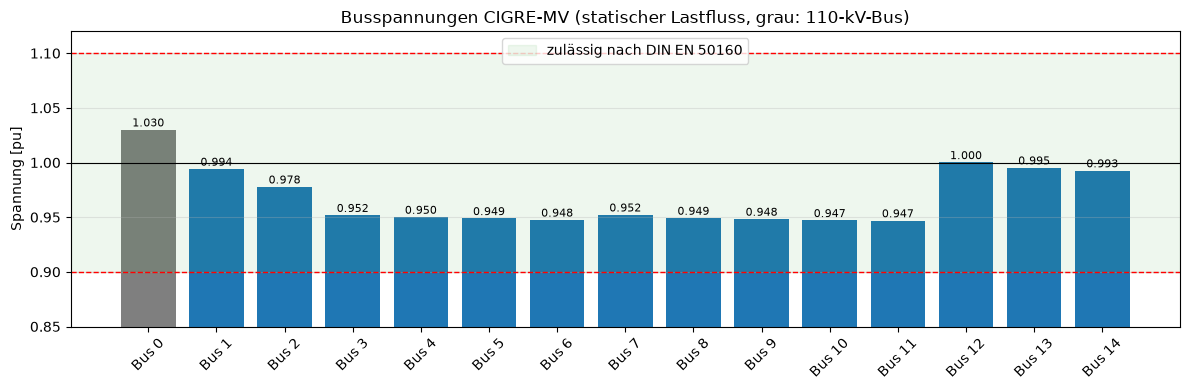

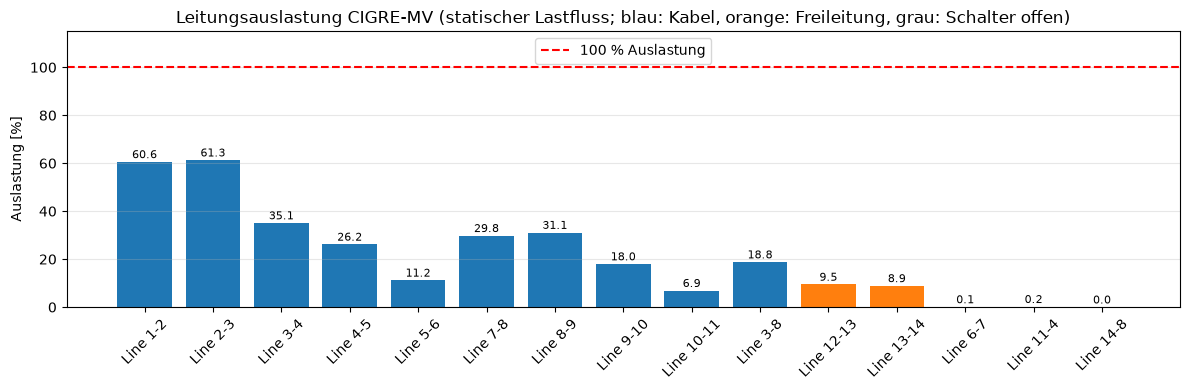

In [26]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = ["tab:gray" if v == 110 else "tab:blue" for v in net.bus.vn_kv]
ax.bar(bus_static["Bus"], bus_static["U [pu]"], color=colors)
ax.axhspan(V_MIN, V_MAX, color="tab:green", alpha=0.08, label="zulässig nach DIN EN 50160")
ax.axhline(V_MIN, color="red", ls="--", lw=1)
ax.axhline(V_MAX, color="red", ls="--", lw=1)
ax.axhline(1.0, color="black", lw=0.8)
for x, v in enumerate(bus_static["U [pu]"]):
    ax.text(x, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
ax.set_ylim(0.85, 1.12)
ax.set_ylabel("Spannung [pu]")
ax.set_title("Busspannungen CIGRE-MV (statischer Lastfluss, grau: 110-kV-Bus)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["lightgray" if s == "offen" else ("tab:orange" if a == "Freileitung" else "tab:blue")
          for s, a in zip(line_static["Schalter"], line_static["Art"])]
ax.bar(line_static["Leitung"], line_static["Auslastung [%]"], color=colors)
ax.axhline(100, color="red", ls="--", lw=1.5, label="100 % Auslastung")
for x, v in enumerate(line_static["Auslastung [%]"]):
    ax.text(x, v + 1.5, f"{v:.1f}", ha="center", fontsize=8)
ax.set_ylim(0, 115)
ax.set_ylabel("Auslastung [%]")
ax.set_title("Leitungsauslastung CIGRE-MV (statischer Lastfluss; blau: Kabel, orange: Freileitung, grau: Schalter offen)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Kennzahlen statischer Lastfluss**

| Größe | Wert | Ort |
|---|---|---|
| Konvergenz | ja, 4 Newton-Raphson-Iterationen | – |
| niedrigste Spannung (20 kV) | 0,947 pu (−5,3 %) | Bus 11 |
| höchste Spannung (20 kV) | 1,000 pu | Bus 12 |
| höchste Leitungsauslastung | 61,3 % | Line 2-3 (Line 1-2: 60,6 %) |
| Trafoauslastung | 93,8 % bzw. 84,7 % | Trafo 0-1 bzw. Trafo 0-12 |
| Bezug aus dem 110-kV-Netz | 43,2 MW bei 44,7 MW Last und 1,7 MW Erzeugung | – |
| Netzverluste | 0,16 MW (0,4 % der Last) | – |

**Interpretation.** Alle Busspannungen liegen im Band 0,9 bis 1,1 pu nach DIN EN 50160. Keine Leitung ist überlastet. Den größten Spannungsfall gibt es in Abgang 1. Über die Kabel Line 1-2 und Line 2-3 (zusammen 7,2 km) fließt die gesamte Last hinter Bus 2, die Spannung fällt dort von 0,994 auf 0,952 pu. Dahinter sind die Kabel kurz und schwächer belastet, die Spannung sinkt nur noch bis 0,947 pu. Abgang 2 (Freileitungen) versorgt außer der großen Last an Bus 12 nur kleine Lasten. Die Spannung bleibt dort nahe 1,0 pu.

Am stärksten belastet sind die Transformatoren (bis 94 %). Sie tragen die großen Ersatzlasten an Bus 1 und Bus 12. Weil die Transformatoren keinen Stufensteller haben, fällt die Spannung bereits zwischen dem 110-kV-Netz (1,03 pu) und Bus 1 auf 0,994 pu.

Der statische Fall ist ein Grenzfall: Alle Lasten und alle Erzeuger arbeiten gleichzeitig mit ihrer Bemessungsleistung. Die Windenergieanlage (1,5 MW an Bus 7) entlastet dabei die Leitungen 1-2 und 2-3. Ohne die dezentralen Erzeuger (`with_der=False`) sinkt die Spannung auf 0,923 pu und Line 2-3 ist zu 97 % ausgelastet. Wie aussagekräftig der statische Fall ist, hängt also stark davon ab, ob Wind und PV zum Zeitpunkt der Höchstlast tatsächlich einspeisen. Das untersucht die saisonale Simulation.

**Literaturabgleich.** DIN EN 50160 fordert in Mittelspannungsnetzen, dass 99 % der 10-Minuten-Mittelwerte einer Woche innerhalb von ±10 % der vereinbarten Versorgungsspannung liegen. Diese Bedingung ist erfüllt. In der Netzplanung steht der Mittelspannung allerdings nur ein Teil dieses Bandes zur Verfügung, weil auch im Ortsnetztransformator und im Niederspannungsnetz Spannung abfällt. Ein Spannungsfall von gut 5 % im Mittelspannungsnetz ist deshalb zulässig, verbraucht aber einen merklichen Teil der Reserve. Die Kabelabgänge des CIGRE-Netzes sind als offene Ringe aufgebaut (S2, S3). Fällt ein Abschnitt aus, wird der Ring über den Trennschalter geschlossen und eine Seite übernimmt zusätzliche Last. Die Reserve von knapp 40 % auf Line 1-2 und Line 2-3 ist deshalb für die Wiederversorgung wichtig [13]. Die Netzparameter entsprechen [13] in der Umsetzung von pandapower [14].

### 3.2 Saisonale Simulation

Für die saisonale Simulation wird die Simulationssoftware aus `simulation.py` verwendet (Beschreibung siehe `README.md`). Die Profile werden über die Elementnamen zugeordnet:

| Element | Profil | Skalierung |
|---|---|---|
| `Load R…` (Wohngebiete) | BDEW H25 mit Dynamisierung | `p_mw` aus [13] = höchste Stundenleistung im Jahr |
| `Load CI…` (Gewerbe/Industrie) | BDEW G25 | `p_mw` aus [13] = höchste Stundenleistung im Jahr |
| `PV …` | Wetter (Einstrahlung, Temperatur), Modul Trina Vertex S+ | `p_mw` aus [13] = installierte Leistung |
| `WKA 7` | Wetter (Wind auf Nabenhöhe), Kennlinie Vestas V90-2.0 MW | `p_mw` aus [13] = Nennleistung |

Der Jahresverbrauch jeder Last wird so gewählt, dass die höchste Stundenleistung des Profils im Jahr 2025 genau dem Wert `p_mw` aus dem CIGRE-Netz entspricht. Der Leistungsfaktor der Lasten bleibt wie in [13]. Simuliert wird je Monat eine typische Woche (Montag bis Sonntag, stündlich).

In [27]:
import simulation as sim
from elements import Diagram, Profile

cigre = sim.init("cigre_mv", pn.create_cigre_network_mv(with_der="pv_wind"), overwrite=True, assignProfiles=True)
cigre

27 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8, PV: 8, WIND: 1


Simulation 'cigre_mv' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 18 load, 9 sgen)
  Herkunft: – | Änderungen: 0 | Ergebnisse: keine | letzter Lauf: –

In [28]:
loads = cigre.elements("load")[["Bus", "Profil", "Skalierung"]]
loads["Höchstleistung [MW]"] = cigre.net.load.set_index("name").loc[loads.index, "p_mw"]
loads

,Bus,Profil,Skalierung,Höchstleistung [MW]
Name,,,,
Load R1,Bus 1,HAUSHALT,66.157.911 kWh/a,14.99400
Load R3,Bus 3,HAUSHALT,1.219.778 kWh/a,0.27645
Load R4,Bus 4,HAUSHALT,1.904.566 kWh/a,0.43165
Load R5,Bus 5,HAUSHALT,3.209.943 kWh/a,0.72750
Load R6,Bus 6,HAUSHALT,2.418.157 kWh/a,0.54805
Load R8,Bus 8,HAUSHALT,2.589.354 kWh/a,0.58685
Load R10,Bus 10,HAUSHALT,2.097.163 kWh/a,0.47530
Load R11,Bus 11,HAUSHALT,1.455.174 kWh/a,0.32980
Load R12,Bus 12,HAUSHALT,66.157.911 kWh/a,14.99400


In [29]:
cigre.runSimulation()

Simulation 'cigre_mv': 2016 Lastflüsse in 66 s, nicht konvergiert: 0


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

In [30]:
cigre.summary()

Zeitschritte                                                         2016
konvergiert                                                          2016
U min [pu]                                                          0.951
U max [pu]                                                           1.03
Stunden U < 0.9                                                         0
Stunden U > 1.1                                                         0
Leitung max [%]                                                      75.6
Stunden Leitung > 100 %                                                 0
Trafo max [%]                                                        82.0
Stunden Trafo > 100 %                                                   0
Stunden Rückspeisung ins vorgelagerte Netz                              0
max. Rückspeisung [MW]                                                0.0
Energie Lasten [MWh]                                              43722.0
Energie Erzeuger [MWh]                

In [31]:
cigre.summary(by="month")

,Zeitschritte,konvergiert,U min [pu],U max [pu],Stunden U < 0.9,Stunden U > 1.1,Leitung max [%],Stunden Leitung > 100 %,Trafo max [%],Stunden Trafo > 100 %,Stunden Rückspeisung ins vorgelagerte Netz,max. Rückspeisung [MW],Energie Lasten [MWh],Energie Erzeuger [MWh]
Monat,,,,,,,,,,,,,,
Januar,168,168,0.9523,1.03,0,0,75.1,0,82.0,0,0,0.0,4248.8,117.3
Februar,168,168,0.9510,1.03,0,0,75.6,0,81.4,0,0,0.0,4177.1,78.5
März,168,168,0.9592,1.03,0,0,69.4,0,73.6,0,0,0.0,3881.9,56.0
April,168,168,0.9716,1.03,0,0,57.5,0,65.7,0,0,0.0,3656.1,52.6
Mai,168,168,0.9792,1.03,0,0,49.2,0,55.2,0,0,0.0,3262.5,71.3
Juni,168,168,0.9775,1.03,0,0,52.4,0,57.5,0,0,0.0,3228.4,81.7
Juli,168,168,0.9792,1.03,0,0,50.3,0,56.6,0,0,0.0,3180.9,40.4
August,168,168,0.9804,1.03,0,0,49.3,0,55.4,0,0,0.0,3137.0,51.8
September,168,168,0.9768,1.03,0,0,53.1,0,60.1,0,0,0.0,3225.1,91.9


### 3.3 Spannungen an allen Bussen

Die erste Tabelle fasst die Spannungen jedes Busses über alle 2016 simulierten Stunden zusammen. Die beiden folgenden Tabellen zeigen die niedrigste und die höchste Spannung je Bus und Monat. Alle Stundenwerte stehen zusätzlich in `simulations/cigre_mv/results/vm_pu.csv`.

In [32]:
res = cigre.results
vm = res.vm_pu
fmt_t = lambda s: s.dt.strftime("%a %d.%m. %H:%M")

bus_table = pd.DataFrame({
    "U_n [kV]": cigre.net.bus.set_index("name").loc[vm.columns, "vn_kv"],
    "U min [pu]": vm.min(),
    "Zeitpunkt min": fmt_t(vm.idxmin()),
    "U Mittel [pu]": vm.mean(),
    "U max [pu]": vm.max(),
    "Zeitpunkt max": fmt_t(vm.idxmax()),
    "statisch [pu]": bus_static.set_index("Bus")["U [pu]"],
})
bus_table["Spannweite [%]"] = (bus_table["U max [pu]"] - bus_table["U min [pu]"]) * 100
bus_table.index.name = "Bus"
bus_table.round(4)

,U_n [kV],U min [pu],Zeitpunkt min,U Mittel [pu],U max [pu],Zeitpunkt max,statisch [pu],Spannweite [%]
Bus,,,,,,,,
Bus 0,110.0,1.0300,Mon 06.01. 00:00,1.0300,1.0300,Mon 06.01. 00:00,1.0300,0.0000
Bus 1,20.0,1.0024,Fri 19.12. 17:00,1.0152,1.0246,Mon 08.09. 03:00,0.9941,2.2181
Bus 2,20.0,0.9847,Wed 05.02. 18:00,1.0070,1.0248,Thu 11.09. 03:00,0.9778,4.0046
Bus 3,20.0,0.9567,Wed 05.02. 18:00,0.9937,1.0246,Thu 11.09. 03:00,0.9518,6.7887
Bus 4,20.0,0.9551,Wed 05.02. 18:00,0.9929,1.0242,Thu 11.09. 03:00,0.9501,6.9146
Bus 5,20.0,0.9540,Wed 05.02. 18:00,0.9923,1.0240,Thu 11.09. 03:00,0.9489,7.0010
Bus 6,20.0,0.9527,Wed 05.02. 18:00,0.9917,1.0237,Thu 11.09. 03:00,0.9475,7.1032
Bus 7,20.0,0.9528,Wed 05.02. 18:00,0.9930,1.0278,Sat 14.06. 03:00,0.9522,7.5020
Bus 8,20.0,0.9528,Wed 05.02. 18:00,0.9921,1.0254,Thu 11.09. 03:00,0.9492,7.2612


In [37]:
month_of = res.info["month"].map(lambda m: Month[m].label)
order = [m.label for m in Month]

u_min_month = vm.groupby(month_of).min().T[order]
u_min_month.index.name = "U min [pu]"
u_min_month.style.format("{:.3f}").background_gradient(cmap="RdYlGn", vmin=0.92, vmax=1.03, axis=None)

AttributeError: The '.style' accessor requires jinja2

In [ ]:
u_max_month = vm.groupby(month_of).max().T[order]
u_max_month.index.name = "U max [pu]"
u_max_month.style.format("{:.3f}").background_gradient(cmap="RdYlGn_r", vmin=1.0, vmax=1.08, axis=None)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.022,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.023,1.023
Bus 2,1.022,1.021,1.021,1.022,1.022,1.024,1.022,1.023,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.017,1.019,1.018,1.024,1.019,1.022,1.025,1.021,1.022,1.022
Bus 4,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.021
Bus 5,1.020,1.019,1.017,1.019,1.018,1.023,1.018,1.021,1.024,1.021,1.021,1.021
Bus 6,1.020,1.018,1.016,1.018,1.017,1.023,1.018,1.021,1.024,1.020,1.020,1.021
Bus 7,1.025,1.023,1.020,1.022,1.020,1.028,1.020,1.024,1.028,1.024,1.025,1.026
Bus 8,1.022,1.020,1.018,1.020,1.018,1.025,1.019,1.022,1.025,1.022,1.022,1.023


### 3.4 Spannungen Monat für Monat

Je Monat ein Diagramm mit allen Bussen. Rot gestrichelt sind die Grenzen 0,9 und 1,1 pu nach DIN EN 50160 eingezeichnet. Die senkrechte Markierung zeigt den Zeitpunkt der niedrigsten Spannung der Woche.

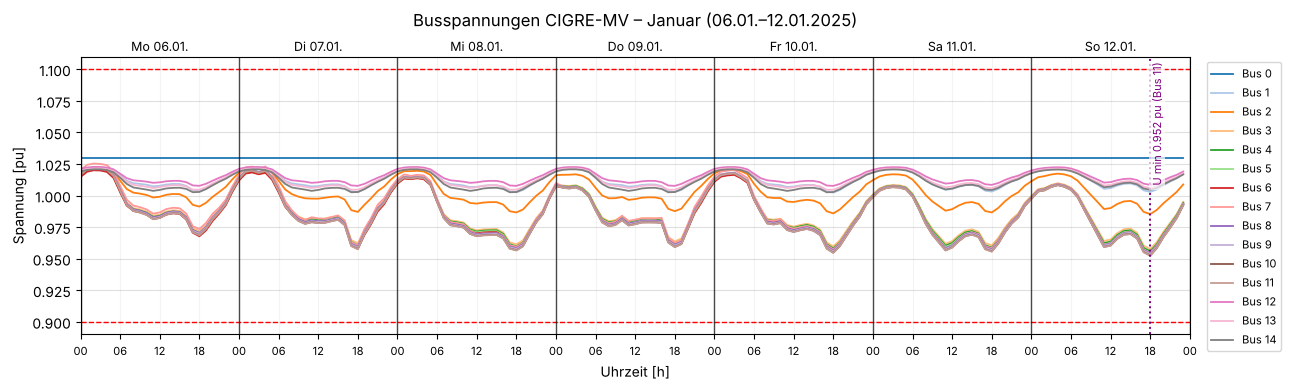

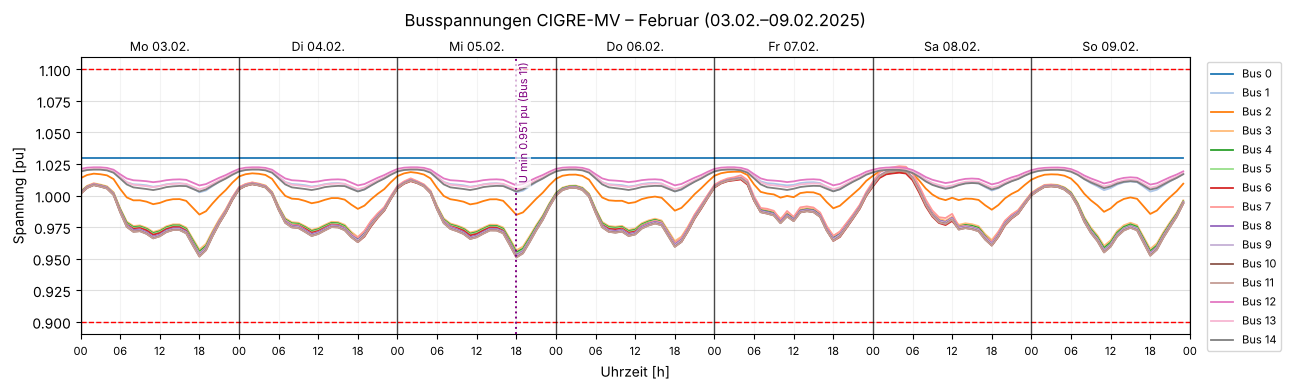

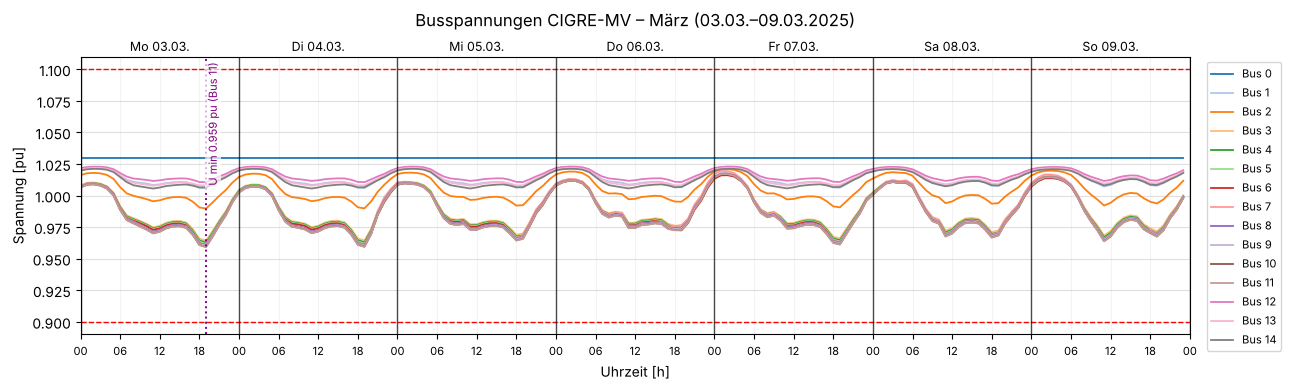

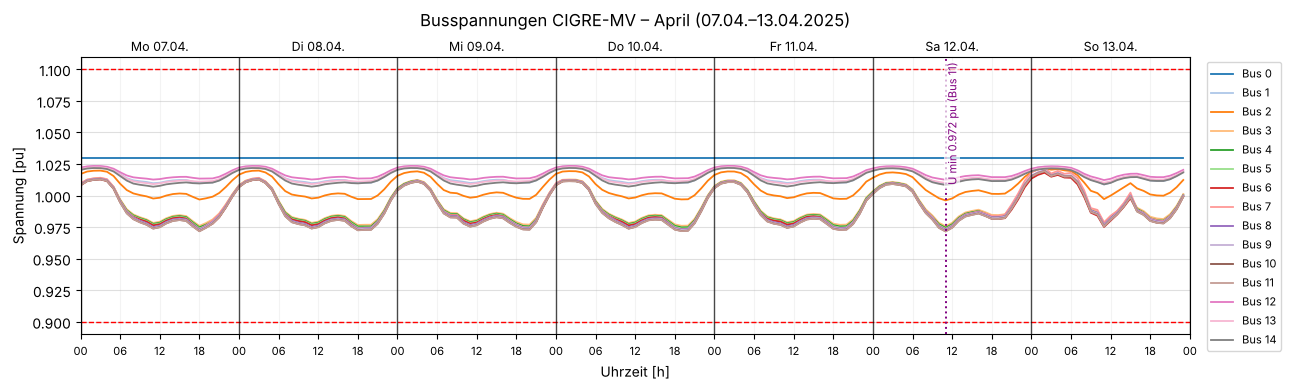

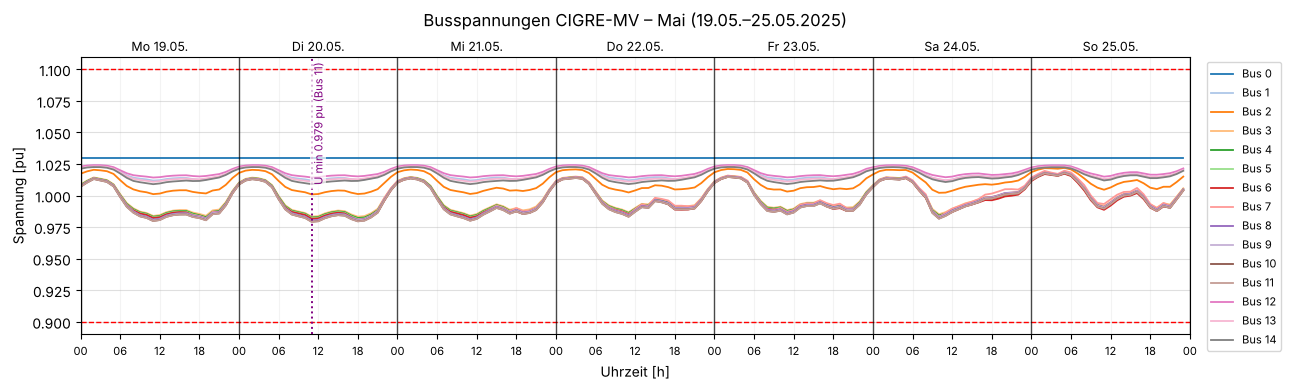

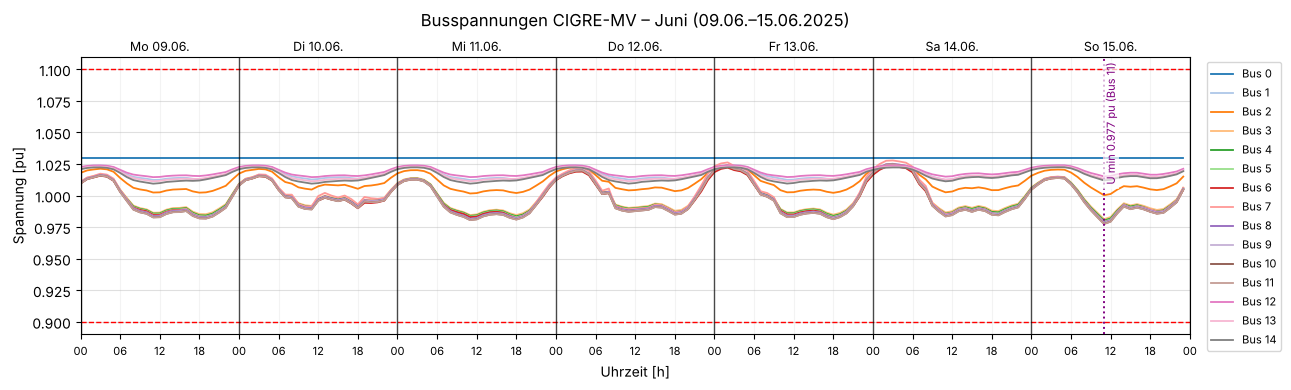

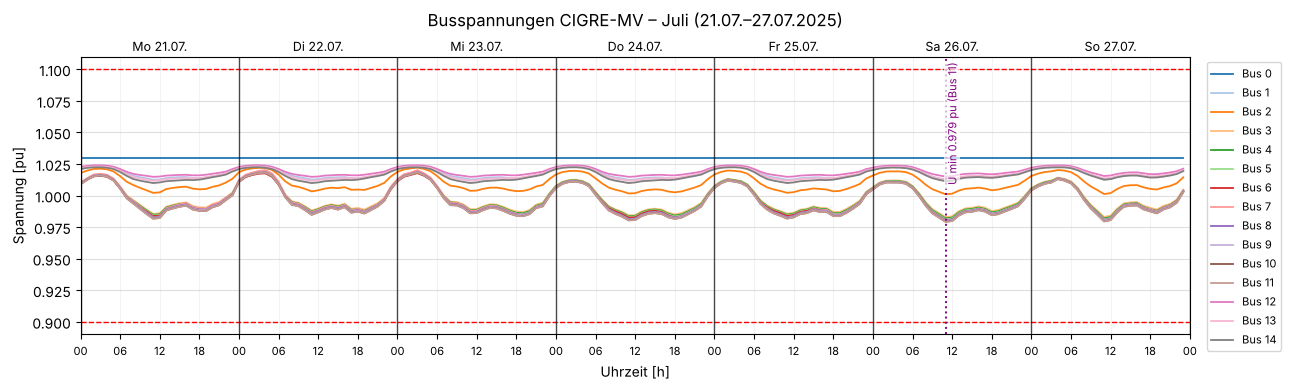

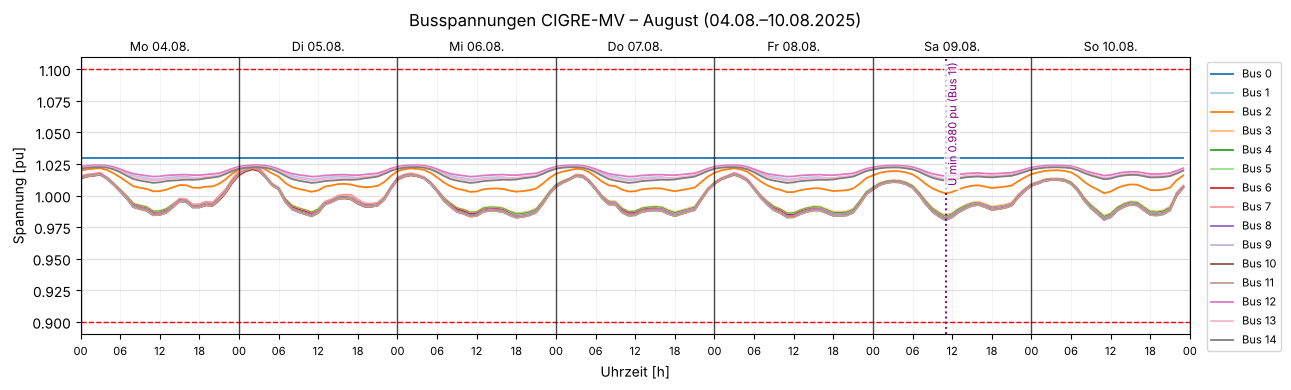

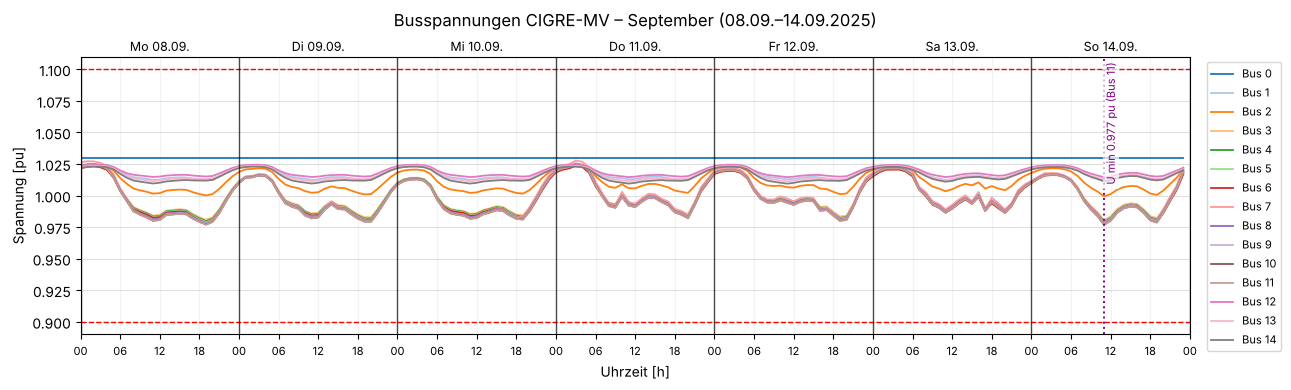

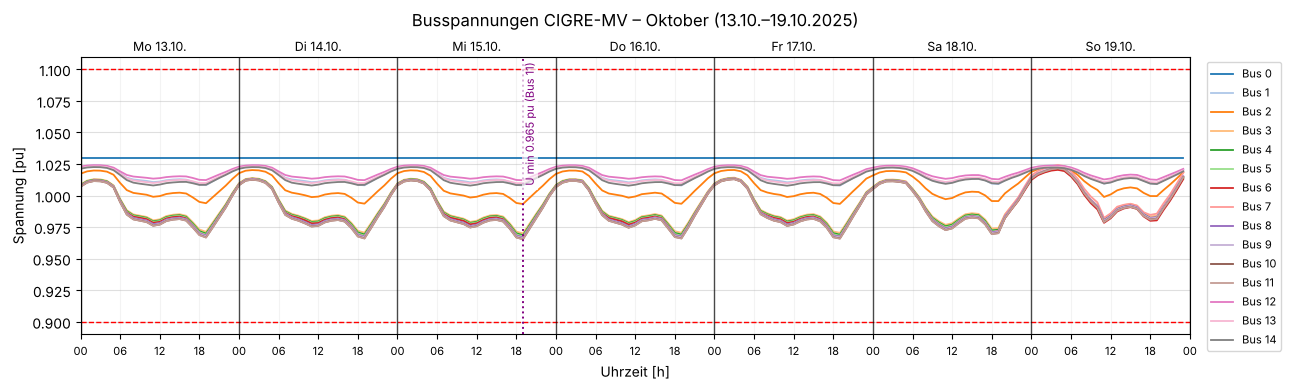

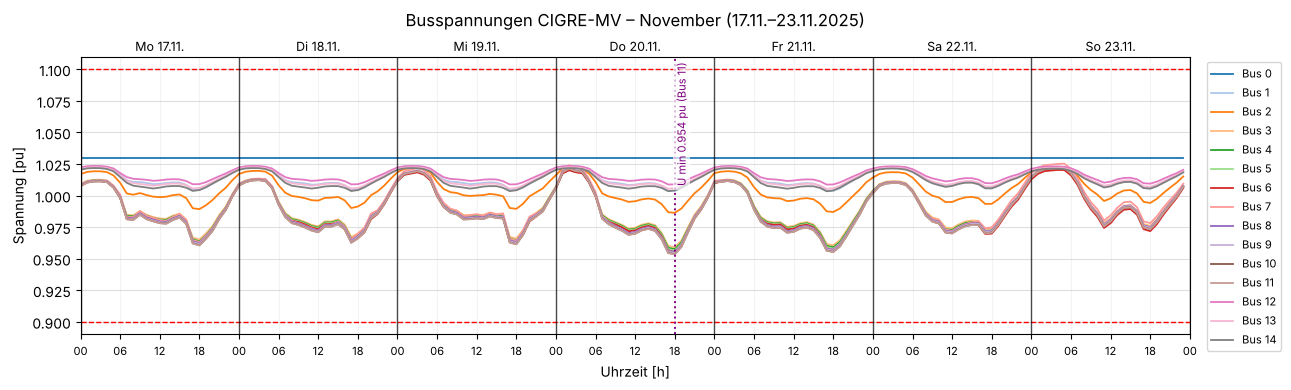

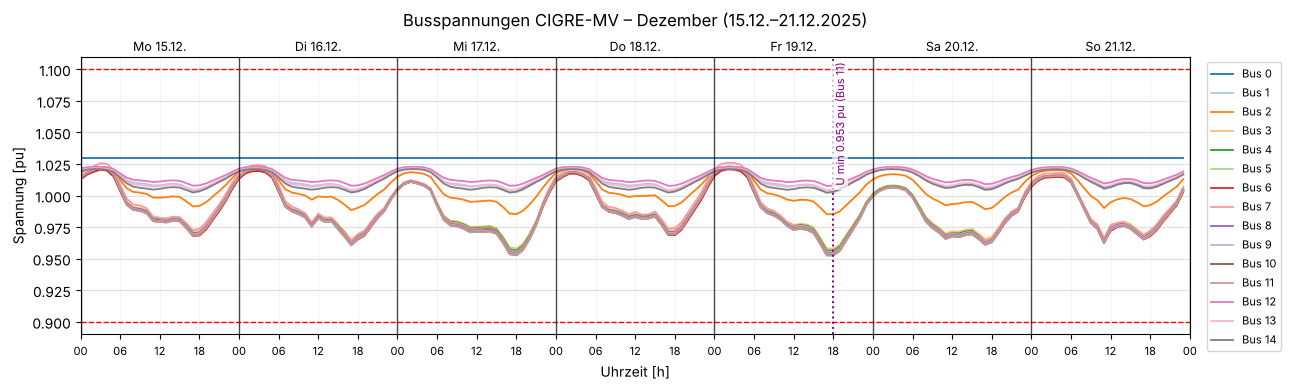

In [ ]:
for m in Month:
    week = vm[res.info["month"] == m.name]
    t_min = week.min(axis=1).idxmin()
    bus_min = week.loc[t_min].idxmin()
    cigre.createDiagram(Diagram.VOLTAGE, months=m,
                        title="Busspannungen CIGRE-MV",
                        markers=[("purple", t_min, f"U min {week.loc[t_min, bus_min]:.3f} pu ({bus_min})", ":")])

### 3.5 Leitungsauslastung Monat für Monat

Je Monat ein Diagramm mit allen Leitungen, deren Trennschalter geschlossen sind. Die Leitungen 6-7, 11-4 und 14-8 führen wegen der offenen Trennschalter nur Ladestrom (unter 1 %) und sind deshalb nicht dargestellt. Rot gestrichelt ist die Grenze 100 % eingezeichnet. Die senkrechte Markierung zeigt den Zeitpunkt der höchsten Auslastung der Woche.

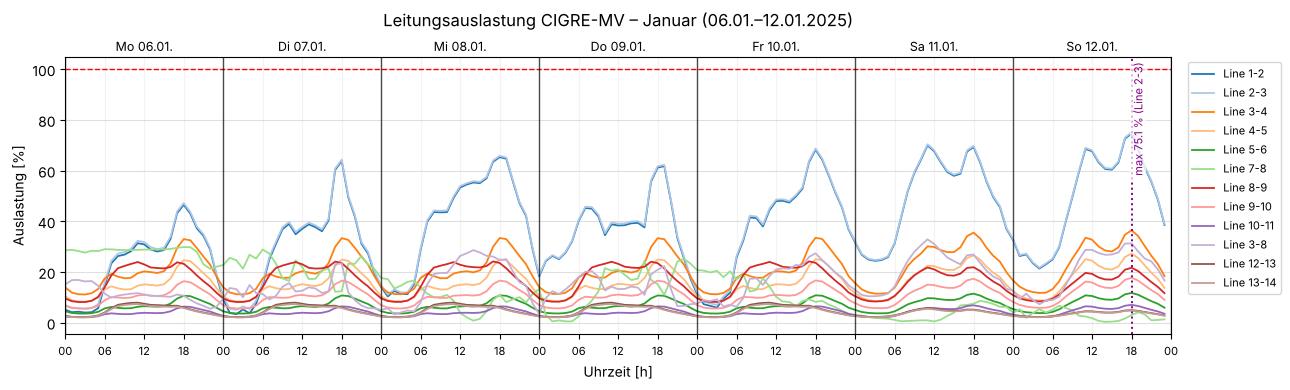

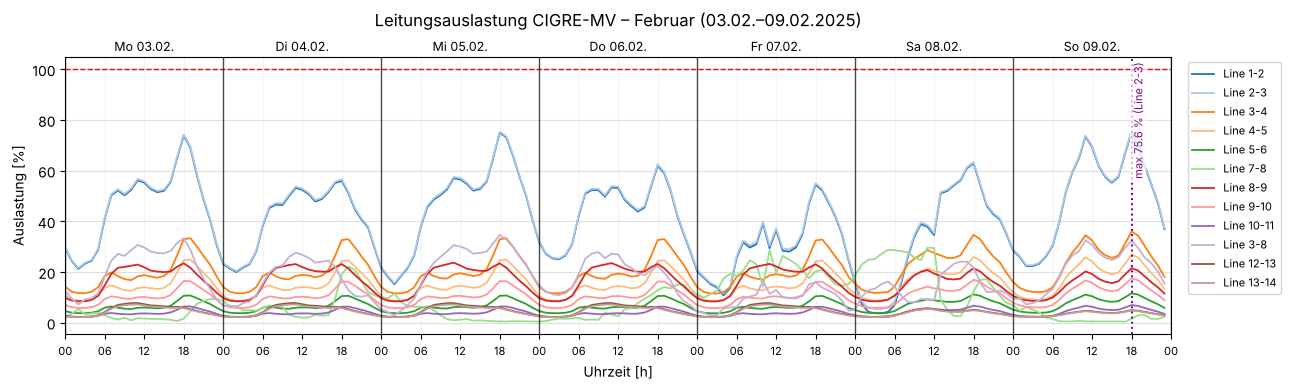

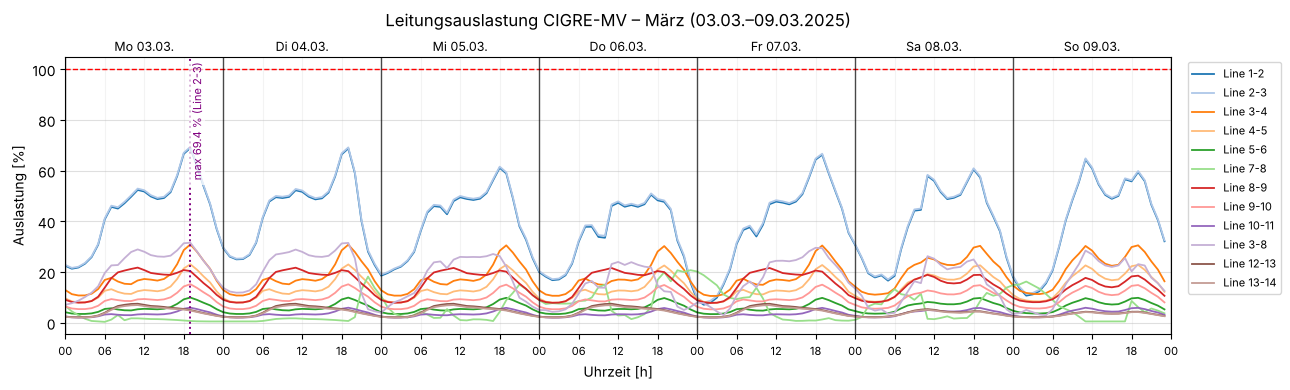

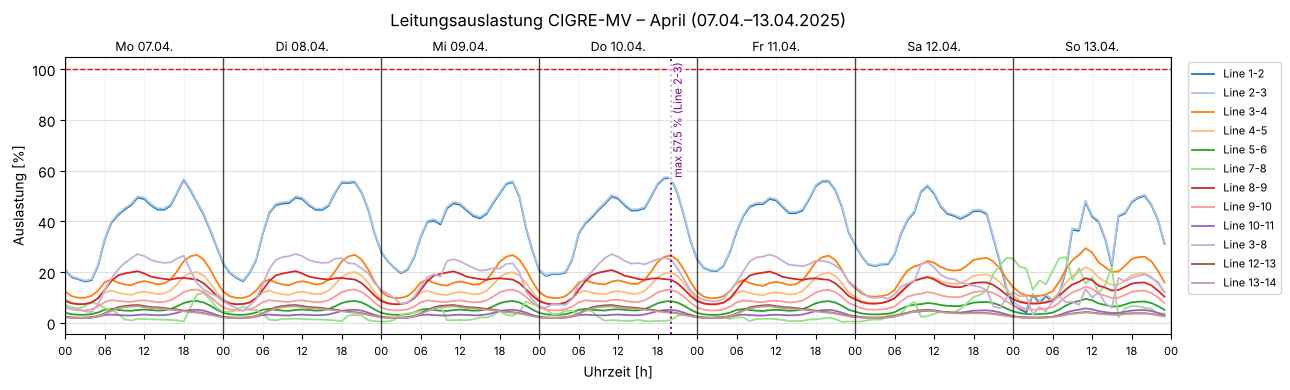

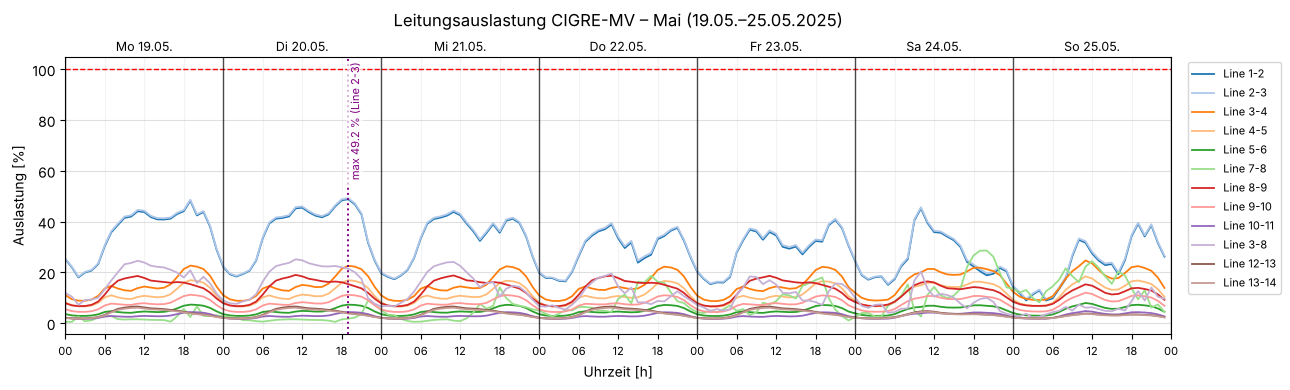

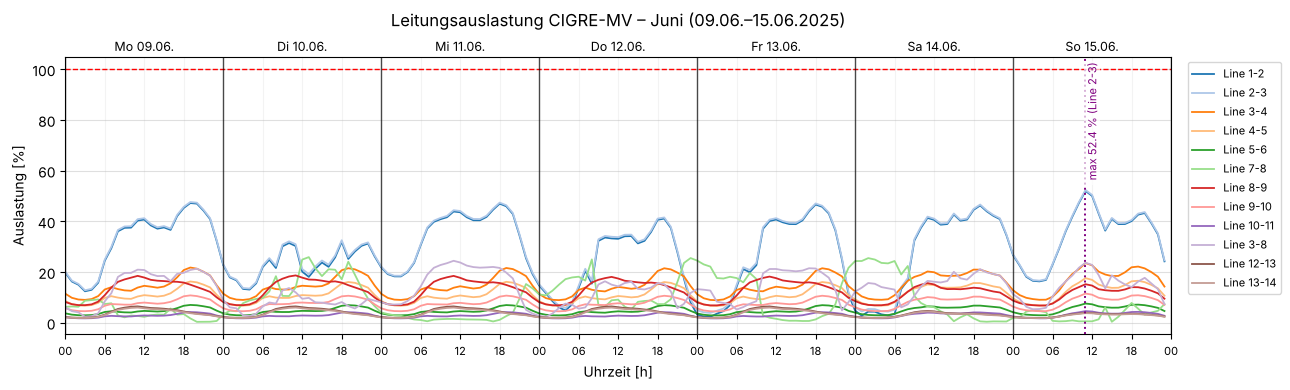

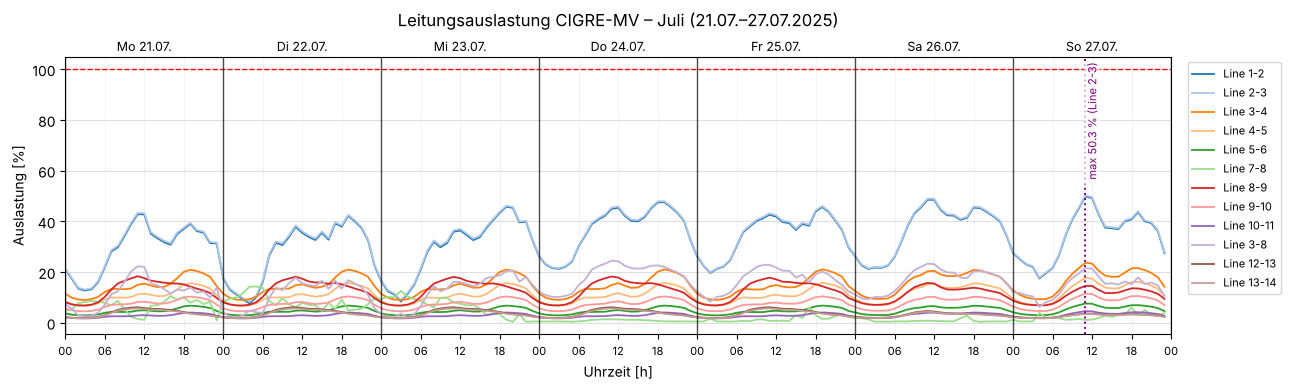

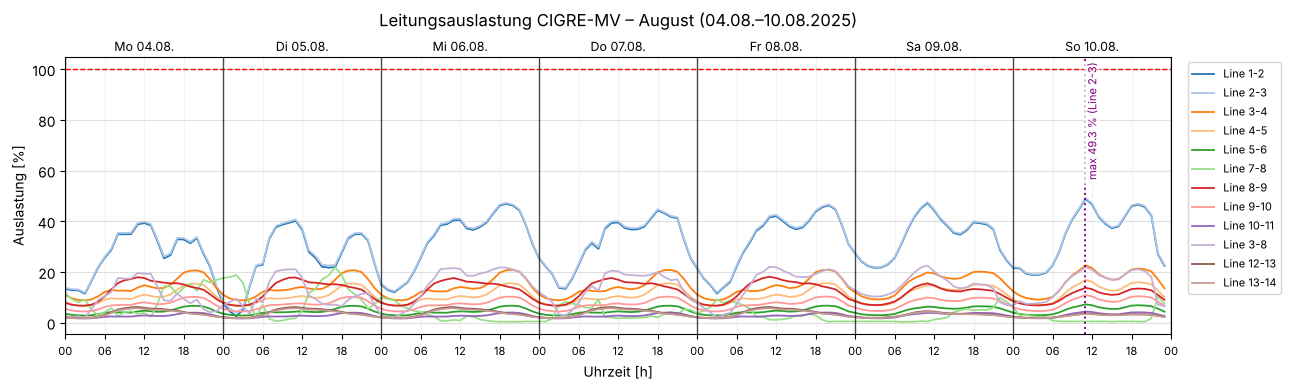

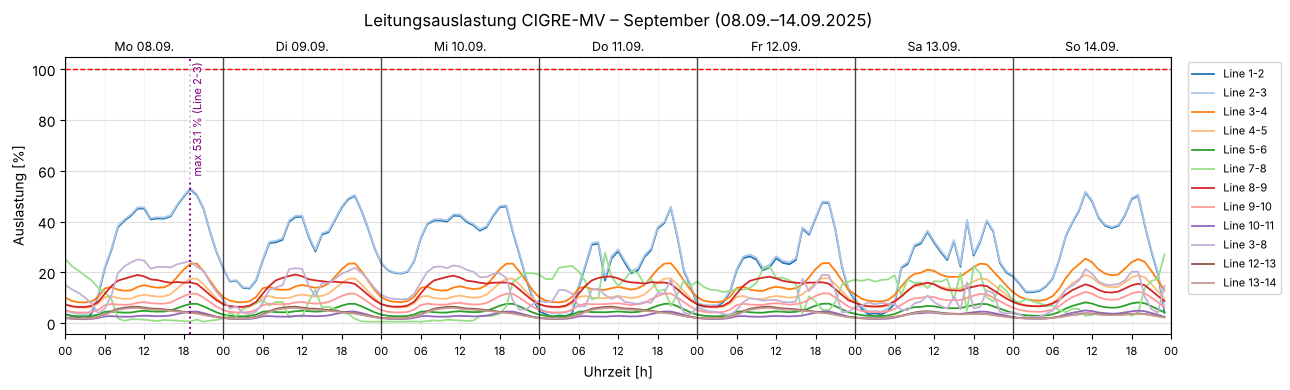

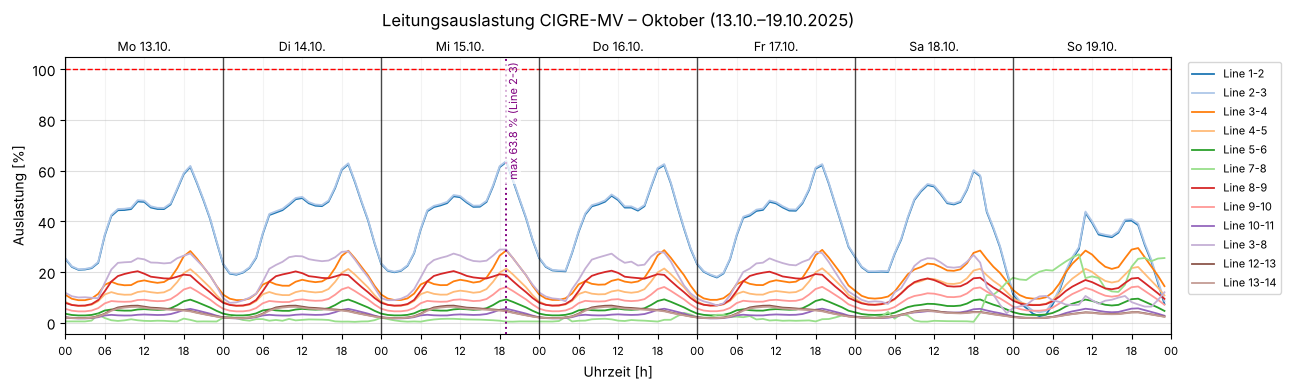

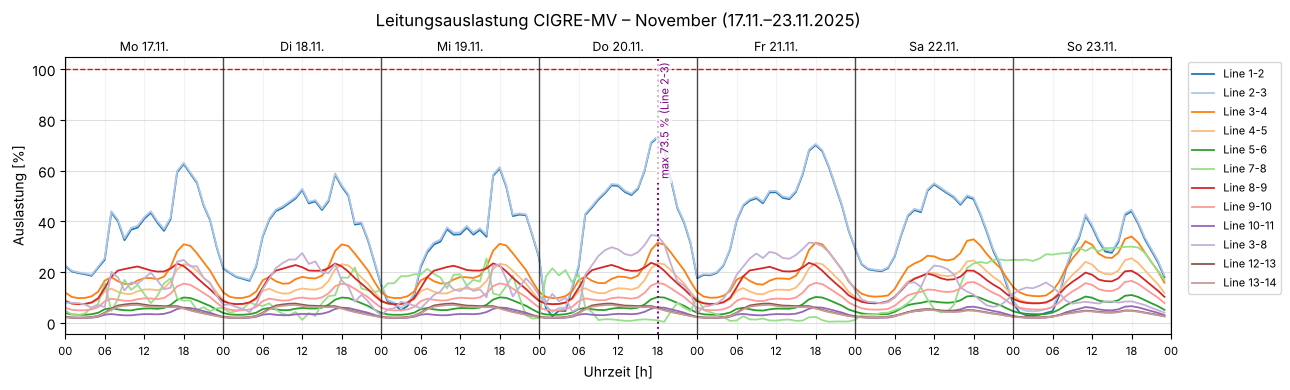

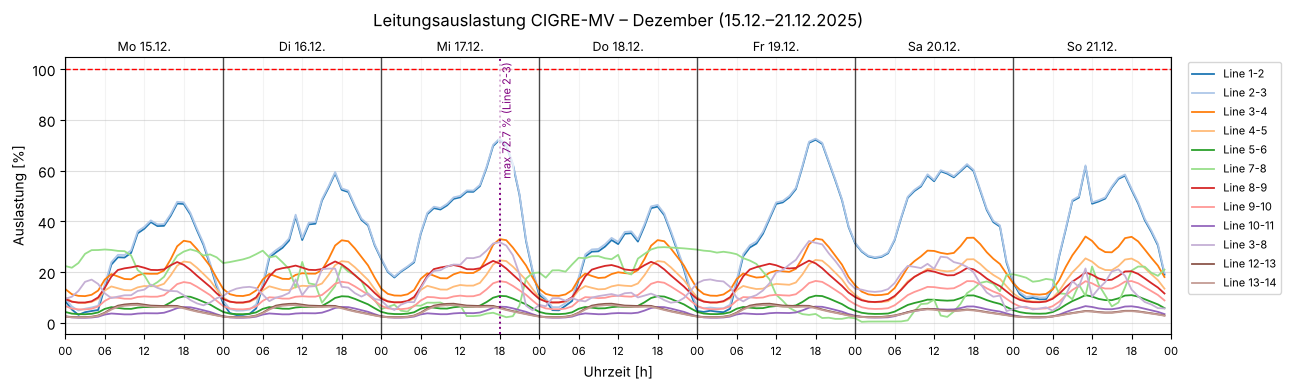

In [ ]:
ll = res.line_loading
closed_lines = [n for i, n in cigre.net.line.name.items() if i not in open_lines]

for m in Month:
    week = ll.loc[res.info["month"] == m.name, closed_lines]
    t_max = week.max(axis=1).idxmax()
    line_max = week.loc[t_max].idxmax()
    cigre.createDiagram(Diagram.LINE_LOADING, elements=closed_lines, months=m,
                        title="Leitungsauslastung CIGRE-MV",
                        markers=[("purple", t_max, f"max {week.loc[t_max, line_max]:.1f} % ({line_max})", ":")])

Zur Einordnung: höchste Auslastung jeder Leitung je Monat in %.

In [ ]:
l_max_month = ll[closed_lines].groupby(month_of).max().T[order]
l_max_month.index.name = "Auslastung max [%]"
l_max_month.style.format("{:.1f}").background_gradient(cmap="YlOrRd", vmin=0, vmax=100, axis=None)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Auslastung max [%],,,,,,,,,,,,
Line 1-2,74.7,75.2,69.0,57.1,48.8,52.0,49.9,48.9,52.8,63.4,73.1,72.3
Line 2-3,75.1,75.6,69.4,57.5,49.2,52.4,50.3,49.3,53.1,63.8,73.5,72.7
Line 3-4,36.5,36.0,30.9,29.5,24.7,23.6,23.7,22.7,25.4,29.5,34.1,34.1
Line 4-5,27.3,26.9,23.1,22.0,18.4,17.6,17.7,16.9,19.0,22.0,25.5,25.5
Line 5-6,11.8,11.6,10.0,9.5,8.0,7.6,7.6,7.3,8.2,9.5,11.0,11.0
Line 7-8,29.9,29.6,20.8,26.0,28.6,25.9,14.4,21.9,27.8,27.0,30.1,29.9
Line 8-9,24.2,23.7,21.8,20.8,19.0,18.7,18.4,18.2,19.1,20.5,23.7,24.6
Line 9-10,17.7,17.5,15.3,14.3,12.0,11.5,11.5,11.0,12.3,14.3,16.6,16.6
Line 10-11,7.1,7.0,6.0,5.7,4.8,4.6,4.6,4.5,5.0,5.7,6.6,6.6


Die beiden Transformatoren 110/20 kV im Überblick über alle 12 Wochen:

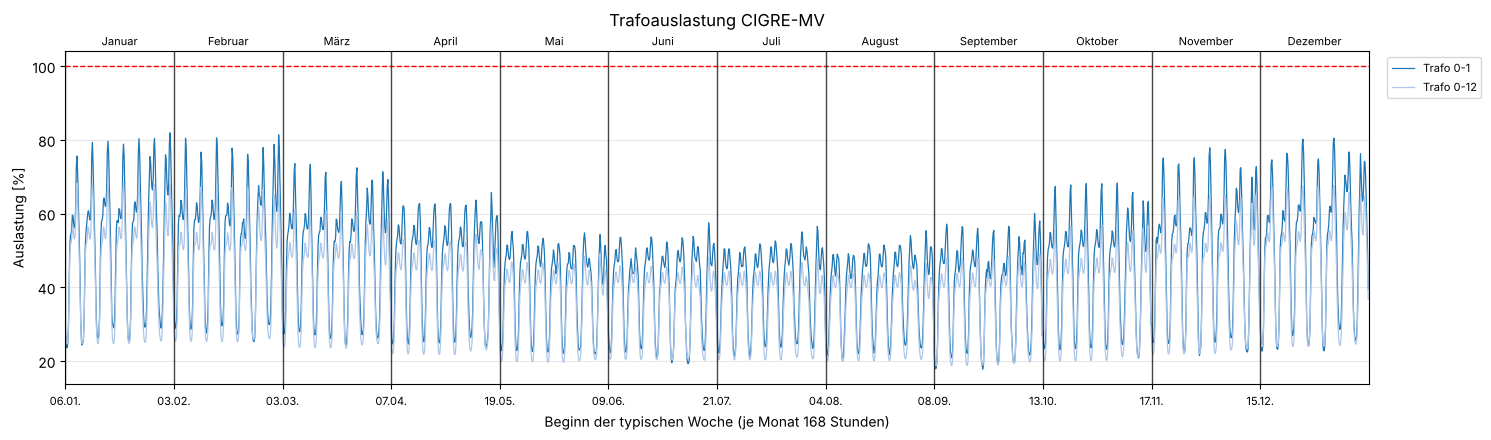

In [ ]:
cigre.createDiagram(Diagram.TRAFO_LOADING, layout="overview", title="Trafoauslastung CIGRE-MV")

### 3.6 Kennzahlen, Interpretation und Literaturabgleich

**Kennzahlen saisonale Simulation (12 typische Wochen, 2016 Stunden)**

| Größe | Wert | Ort und Zeitpunkt |
|---|---|---|
| Konvergenz | alle 2016 Lastflüsse | – |
| niedrigste Spannung | 0,951 pu | Bus 11, Mi 05.02. 18:00 |
| höchste Spannung (20 kV) | 1,028 pu | Bus 7, Sa 14.06. 03:00 |
| Stunden außerhalb 0,9 bis 1,1 pu | 0 | – |
| höchste Leitungsauslastung | 75,6 % | Line 2-3, So 09.02. 18:00 |
| Stunden mit Leitung > 100 % | 0 | – |
| höchste Trafoauslastung | 82,0 % | Trafo 0-1, So 12.01. 18:00 |
| Bezug aus dem 110-kV-Netz | 9,1 bis 36,9 MW, keine Rückspeisung | – |
| Energie Lasten / Erzeuger | 43 722 MWh / 928 MWh (Erzeugung = 2,1 % der Last) | – |

| Monat | Jan | Feb | Mär | Apr | Mai | Jun | Jul | Aug | Sep | Okt | Nov | Dez |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| U min [pu] | 0,952 | 0,951 | 0,959 | 0,972 | 0,979 | 0,978 | 0,979 | 0,980 | 0,977 | 0,965 | 0,954 | 0,953 |
| Leitung max [%] | 75,1 | 75,6 | 69,4 | 57,5 | 49,2 | 52,4 | 50,3 | 49,3 | 53,1 | 63,8 | 73,5 | 72,7 |
| Trafo max [%] | 82,0 | 81,4 | 73,6 | 65,7 | 55,2 | 57,5 | 56,6 | 55,4 | 60,1 | 68,3 | 77,9 | 80,5 |

**Interpretation.**

- **Spannungen:** In allen 2016 Stunden liegen alle Busspannungen im Band nach DIN EN 50160. Der Tiefpunkt (0,951 pu) tritt an einem Winterabend um 18 Uhr auf. Zu dieser Zeit erreicht das Haushaltsprofil H25 sein Maximum und es gibt keine PV-Einspeisung. Nachts und im Sommer steigen die Spannungen bis knapp unter die Spannung des vorgelagerten Netzes (1,03 pu). Die höchste 20-kV-Spannung (1,028 pu, Bus 7) entsteht in einer Sommernacht mit geringer Last und Windeinspeisung. Die Spannung schwankt am Ende von Abgang 1 innerhalb des Jahres um bis zu 7,4 % (Bus 11), in Abgang 2 nur um etwa 2 %.
- **Leitungen und Transformatoren:** Keine Leitung und kein Transformator ist überlastet. Die Auslastung folgt deutlich der Jahreszeit: Im Winter sind die Leitungen bis 76 % ausgelastet, im Sommer nur bis 49 bis 52 %. Ursache sind die Dynamisierung des H25-Profils (höherer Verbrauch im Winter) und das saisonale Gewerbeprofil G25. Die Tagesgänge sind in allen Wochen gleich geformt: niedrig in der Nacht, Mittagsplateau, Abendspitze gegen 18 Uhr.
- **Vergleich mit dem statischen Fall:** Die höchste Leitungsauslastung der Simulation (75,6 %) liegt **über** der des statischen Lastflusses (61,3 %), obwohl keine Last ihre Bemessungsleistung überschreitet. Im statischen Fall speisen Wind und PV mit voller Leistung ein und entlasten die Leitungen. Zur winterlichen Abendspitze liefert die PV keinen Strom und die Windenergieanlage oft nur wenig. Die Simulation liegt deshalb zwischen dem statischen Fall mit Erzeugern (61 %) und ohne Erzeuger (97 %). Die Transformatoren werden dagegen weniger belastet als im statischen Fall (82 % statt 94 %). Die großen Lasten an Bus 1 und Bus 12 erreichen ihr Maximum nicht gleichzeitig, weil das Haushalts- und das Gewerbeprofil zu verschiedenen Zeiten ihre Spitze haben.
- **Erzeugung:** Die Erzeuger decken nur 2,1 % des Verbrauchs. Es tritt keine Rückspeisung in das 110-kV-Netz auf und die Erzeugung hebt die Spannung kaum an. Das Netz ist in dieser Variante deutlich durch die Last bestimmt.

**Literaturabgleich.** 

### 3.7 Bus Spannung Vergleiche

Ich möchte hier jeweils zwei Monate gegenüberstellen, wo die PV Anlagen und Windklaftanlage viel produziert hat und die veränderung der spannung zeigen.

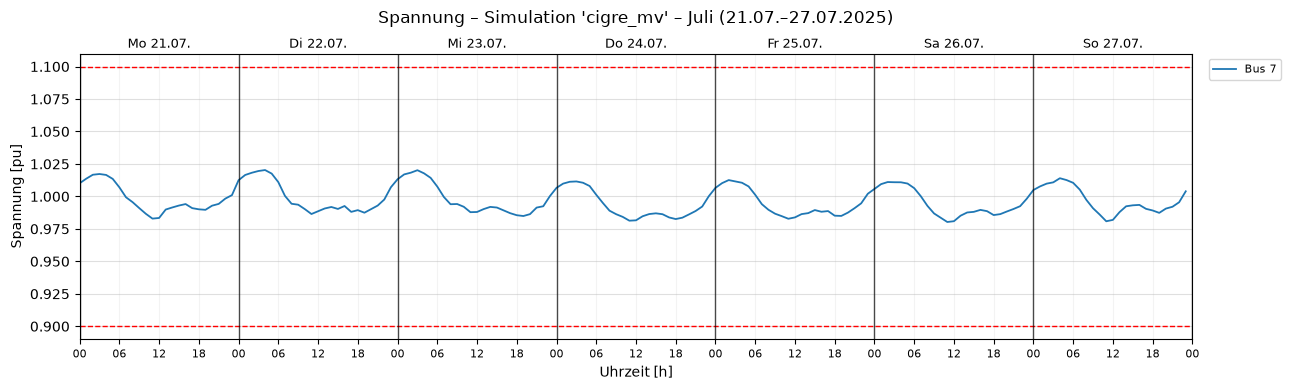

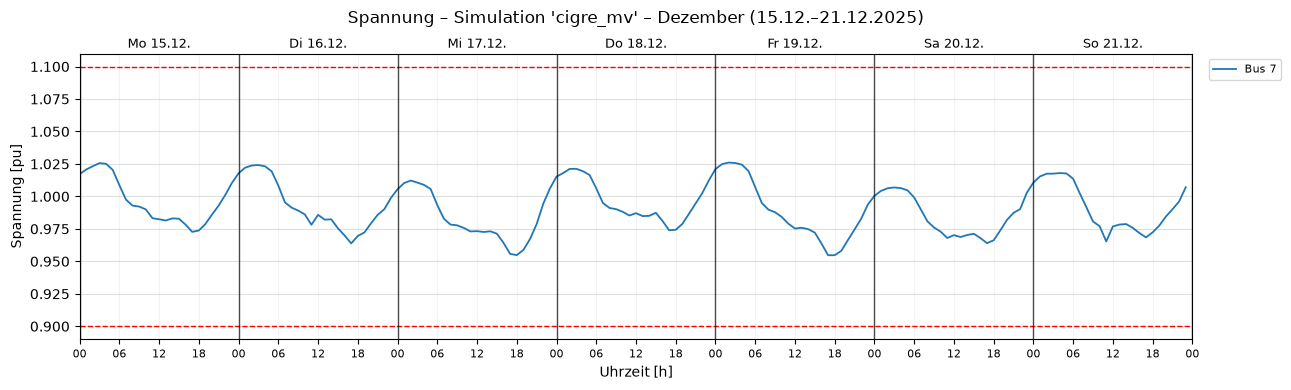

In [36]:
cigre.createDiagram(Diagram.VOLTAGE, elements=["Bus 7"], months=[Month.JULY, Month.DECEMBER])

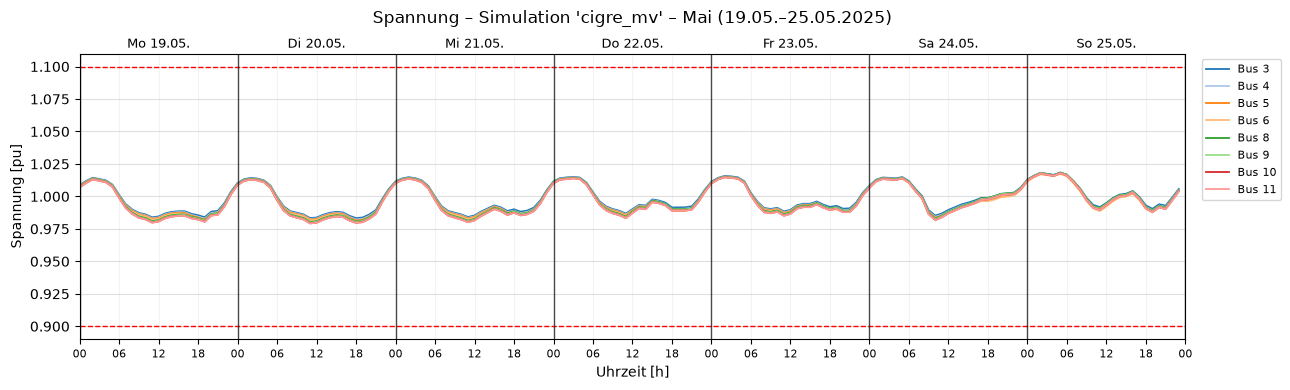

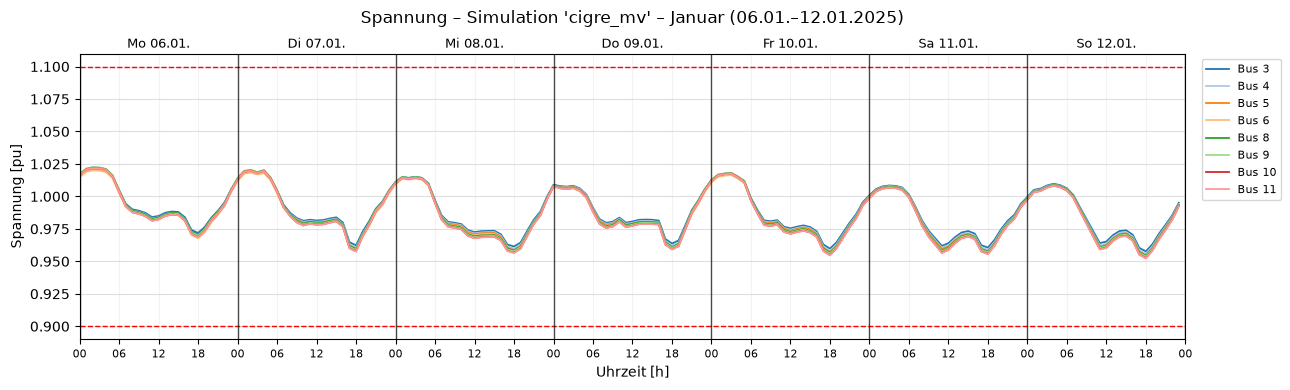

In [40]:
cigre.createDiagram(Diagram.VOLTAGE, elements=["Bus 3", "Bus 4", "Bus 5", "Bus 6", "Bus 8", "Bus 9", "Bus 10", "Bus 11"],
                    months=[Month.MAY, Month.JANUARY])